> **In this repository.** Fine-tuning experiment log for one pretrained backbone. Notebooks 05 to 13 are copies of one shared template: the data, model, metric and training code is the same in each, and only the backbone, its settings and the iterations differ. Each `run_iteration` cell trains one change on `train.csv` and scores it on `val.csv`; the cell after it records the team's accept/reject decision. `test.csv` and `test_unseen.csv` are never read here. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# Fine-tuning experiments: ResNet-50 (timm `resnet50.a1_in1k`)

ResNet-50 with the ImageNet-1k weights of "ResNet strikes back" (`resnet50.a1_in1k`; the same weights family for ResNet-18/34/50/101/152, so the depths are comparable). Generated from `template_notebooks/experiments_TEMPLATE.ipynb` by `make_experiment_notebooks.py`: Sections 2 to 6 are the template's shared code; changes are the runtime switch (0b), only the packages a ResNet needs (0), the model cell (1), Section 3 reduced to the timm ResNet adapter, `decide()` (6c) and the iterations (7).

The notebook implements an experiment design on the final dataset (`downloaded_data/inat_dataset_final`). It trains on `train.csv`, tunes and evaluates on `val.csv`, and **never touches `test.csv` or `test_unseen.csv`**.

## How the notebook is organized

* **Section 1** holds `MODEL_NAME` and `BASE_CONFIG`, an initial configuration. This should be edited to specify the model and hyperparameters.
* **Sections 2 to 6** (data, backbone adapters, metrics, plots, training loop) are shared code and should be identical in every model's notebook so the metrics are comparable.
* **Section 7** is the manual iteration loop: one cell runs an iteration (`run_iteration(name, overrides)`), the next cell records your decision (`accept(name)` or `reject(name)`). Accepted overrides become part of the current configuration, and every later iteration is run on top of it. Decisions are saved in `RUNS_DIR/<MODEL_NAME>/decisions.json`, so the configuration survives a kernel restart.
* Cross-iteration and cross-model comparison lives in `compare_model_runs.ipynb` next to this file; it reads the files each run writes.

## Task encoding

* The head has **one logit per invasive species** (40 classes). `not_invasive` rows have an all-zero target.
* Loss: multi-label `BCEWithLogitsLoss`.
* Binary "is invasive" = `max_c sigmoid(logit_c) >= threshold`; species = `argmax_c` when invasive, else `not_invasive`.
* The threshold is tuned on the validation set to maximize **macro-F1 over the 40 invasive species** (the primary validation metric). All thresholded metrics use that fixed threshold.
* Primary KPI: top-1 accuracy over all 41 labels.

## Outputs

Each iteration writes to `RUNS_DIR/<MODEL_NAME>/<iteration>/`: `config.json` (the effective hyperparameters and the accepted changes it was built on), `history.csv` (per-epoch metrics), `best.pt` (best validation checkpoint by macro-F1, with its threshold), `metrics_final.json` (best checkpoint re-evaluated with TTA), `val_predictions.csv`, and the plots as PNG.

## 0. Environment

In [ ]:
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")

# Install what is missing (Colab ships torch/torchvision/sklearn/pandas/matplotlib already).
_required = {"torchmetrics": "torchmetrics", "timm": "timm", "huggingface_hub": "huggingface_hub"}   # timm downloads the weights via huggingface_hub
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## 0b. Runtime: Colab or local

Switch between running on Colab (Team Drive) and on a local machine here. Only paths (dataset, runs, image-cache file) and the number of loader workers depend on the runtime; nothing that changes the results (batch size, augmentation, schedule) does, so runs from both are comparable.

In [ ]:
RUNTIME = "auto"                 # "auto" (detect Colab), "colab" or "local"
if RUNTIME == "auto":
    RUNTIME = "colab" if IN_COLAB else "local"

if RUNTIME == "colab":
    DATA_ROOT_OVERRIDE = None    # None = the Team Drive dataset (MyDrive/ or Shareddrives/fall-2026-DL-invasive-plants/...)
    RUNS_DIR_OVERRIDE = None     # None = modeling_runs next to downloaded_data on the Drive
    NUM_WORKERS = 2              # Colab gives 2 CPU cores
    IMAGE_CACHE_DIR_OVERRIDE = None   # None = the folder that holds inat_dataset_final (downloaded_data/)
else:
    DATA_ROOT_OVERRIDE = None    # None = ../../downloaded_data/inat_dataset_final relative to this notebook
    RUNS_DIR_OVERRIDE = None     # None = <repo root>/modeling_runs
    NUM_WORKERS = 8
    IMAGE_CACHE_DIR_OVERRIDE = None
print(f"runtime: {RUNTIME} | DATA_ROOT_OVERRIDE={DATA_ROOT_OVERRIDE} | RUNS_DIR_OVERRIDE={RUNS_DIR_OVERRIDE} | "
      f"IMAGE_CACHE_DIR_OVERRIDE={IMAGE_CACHE_DIR_OVERRIDE} | num_workers={NUM_WORKERS}")

runtime: colab | DATA_ROOT_OVERRIDE=None | RUNS_DIR_OVERRIDE=None | IMAGE_CACHE_DIR_OVERRIDE=None | num_workers=2


In [ ]:
import copy, datetime, json, math, random, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.transforms import v2
import timm
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print(f"torch {torch.__version__} | timm {timm.__version__} | torchmetrics {torchmetrics.__version__}")
print(f"device: {DEVICE} | mixed-precision dtype: {AMP_DTYPE if DEVICE.type == 'cuda' else 'disabled (CPU)'}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

# Plot style shared by every notebook so figures are comparable across models.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch 2.11.0+cu130 | timm 1.0.30 | torchmetrics 1.9.0
device: cuda | mixed-precision dtype: torch.bfloat16
NVIDIA RTX PRO 6000 Blackwell Server Edition 95.0 GiB


## 1. Configuration

`BASE_CONFIG` is the initial configuration. Iterations (Section 7) pass a `dict` of overrides; the effective configuration of an iteration is `{**current_configuration, **overrides}`, where the current configuration is `BASE_CONFIG` plus every accepted override so far.

In [ ]:
MODEL_NAME = "resnet50"          # key of BACKBONE_REGISTRY (Section 3)

# DATA_ROOT_OVERRIDE / RUNS_DIR_OVERRIDE / NUM_WORKERS are set in Section 0b (Colab or local).

BASE_CONFIG = {
    # --- data / input ---
    "image_size": 224,                        # network input (design: 224x224)
    "presize": 256,                           # shorter side before the random crop; keeps aspect ratio
    "rrc_scale": (0.75, 1.0),                 # RandomResizedCrop(224, scale=...)
    "hflip_p": 0.5,
    "rotation_deg": 15,                       # RandomRotation(+-15 deg)
    "color_jitter": {"brightness": 0.15, "contrast": 0.15, "saturation": 0.15, "hue": 0.02},
    "val_resize": 256,                        # eval: Resize(shorter side) then CenterCrop(image_size)
    "batch_size": 64,                         # reduce to 32/16 if the GPU runs out of memory
    "num_workers": NUM_WORKERS,               # Section 0b
    # --- architecture: backbone -> pooled features -> dropout -> linear(n_invasive) ---
    "dropout": 0.1,
    "backbone_kwargs": {"drop_path_rate": 0.0},   # read by build_timm: stochastic depth on the residual blocks (0 = off)
    # --- stage 1: frozen backbone, constant LR on the head ---
    "frozen_epochs": 3,
    "frozen_head_lr": 1e-3,
    # --- stage 2: full fine-tuning, 1-cycle cosine schedule ---
    "full_epochs": 20,
    "backbone_lr": 1e-04,                      # peak LR of the backbone (model dependent; ResNet)
    "head_lr": 1e-03,                          # peak LR of the head (ResNet)
    "pct_start": 0.1,
    "weight_decay": 0.01,
    "weight_decay_exclude_1d": True,          # no decay on biases and BatchNorm parameters
    "layer_decay": None,                      # layer-wise LR decay (matches ViT block names; keep None for ResNets)
    "grad_clip_norm": 1.0,
    "amp": True,                              # mixed precision (bf16 if the GPU supports it, else fp16)
    # --- loss / regularization ---
    "loss": "bce",                            # multi-label BCEWithLogitsLoss over the invasive classes
    "bce_pos_weight": None,                   # None = plain BCE; a float scales the positive term (imbalance)
    "label_smoothing": 0.0,                   # BCE targets -> y*(1-eps) + eps/2
    "mixup_alpha": 0.0,                       # 0 = off
    # --- evaluation ---
    "threshold_grid": [round(t, 3) for t in np.linspace(0.01, 0.99, 99)],
    "select_metric": "macro_f1_invasive",     # checkpoint selection + threshold tuning target
    "tta_hflip": True,                        # test-time augmentation for the final evaluation of best.pt
    # --- bookkeeping ---
    "seed": 42,
    "max_batches_per_epoch": None,            # set e.g. 5 to check the pipeline quickly before a real run
}

## 2. Paths and data

The dataset folder is `DATA_ROOT_OVERRIDE` if set, else the Team Drive path on Colab, else the repo-relative path. Only `train.csv` and `val.csv` are read. The last cell of this section decodes every image once into RAM (about 2.4 GB); all iterations train from that cache.

**Image-cache file.** Decoding ~10.5k full-size JPEGs through the Drive mount takes long on Colab, so the cache is also kept as **one file** next to the dataset: `<IMAGE_CACHE_DIR>/image_cache_p<presize>_v<val_resize>_s<image_size>.pt` (about 2.4 GB; `IMAGE_CACHE_DIR` = the folder that holds `inat_dataset_final`, or `IMAGE_CACHE_DIR_OVERRIDE` from Section 0b). If the file exists and was built from the same train/val rows (the stored image paths are compared), it is loaded (one sequential read); otherwise the cache is decoded as before and then saved to that file for the next session. The cached tensors are identical either way.

In [ ]:
_candidates = [DATA_ROOT_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "../../downloaded_data/inat_dataset_final", "downloaded_data/inat_dataset_final"]
DATA_ROOT = next((Path(p) for p in _candidates if p and (Path(p) / "train.csv").exists()), None)
assert DATA_ROOT is not None, f"dataset folder not found; tried {_candidates}"
RUNS_DIR = Path(RUNS_DIR_OVERRIDE) if RUNS_DIR_OVERRIDE else DATA_ROOT.parent.parent / "modeling_runs"
MODEL_DIR = RUNS_DIR / MODEL_NAME
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_ROOT:", DATA_ROOT.resolve()); print("MODEL_DIR:", MODEL_DIR.resolve())

NONE_LABEL = "not_invasive"
train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df = pd.read_csv(DATA_ROOT / "val.csv")

INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}
CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE                   # index N_INVASIVE = not_invasive (no logit, only a target)
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]            # 41 names in index order
assert set(val_df["label"]) <= set(ALL_LABELS), "val has labels that train does not"
assert not set(train_df["observer_id"]) & set(val_df["observer_id"]), "observer leakage between train and val"

for name, df in (("train", train_df), ("val", val_df)):
    df["y"] = df["label"].map(CLASS_TO_IDX)
    print(f"{name}: {len(df):>5} rows | {df['invasive'].sum():>4} invasive | {(~df['invasive']).sum():>4} {NONE_LABEL} | "
          f"{df.loc[df['invasive'], 'label'].nunique()} invasive classes, {df['scientific_name'].nunique()} species")
print(f"{N_INVASIVE} invasive classes -> {N_INVASIVE} logits; '{NONE_LABEL}' is the all-zero target (index {N_INVASIVE})")

DATA_ROOT: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
MODEL_DIR: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs/resnet50
train:  7342 rows | 1186 invasive | 6156 not_invasive | 40 invasive classes, 441 species
val:  3228 rows |  982 invasive | 2246 not_invasive | 40 invasive classes, 441 species
40 invasive classes -> 40 logits; 'not_invasive' is the all-zero target (index 40)


In [ ]:
# Check which image files exist (the download may have gaps; see download_failures.csv).
_failures_file = DATA_ROOT / "download_failures.csv"
if _failures_file.exists():
    try:
        _f = pd.read_csv(_failures_file)
        print(f"download_failures.csv: {len(_f)} rows")
    except pd.errors.EmptyDataError:                 # the download cell writes an empty file when nothing failed
        print("download_failures.csv exists but is empty: no failed downloads")

for name, df in (("train", train_df), ("val", val_df)):
    df["exists"] = df["image_path"].map(lambda p: (DATA_ROOT / p).is_file())
    n_missing = (~df["exists"]).sum()
    if n_missing:
        missing_by_class = df.loc[~df["exists"], "label"].value_counts()
        print(f"{name}: {n_missing} rows without an image file (dropped). Worst classes:\n{missing_by_class.head(8).to_string()}")
    else:
        print(f"{name}: all {len(df)} image files present")
train_df = train_df[train_df["exists"]].reset_index(drop=True)
val_df = val_df[val_df["exists"]].reset_index(drop=True)
assert len(train_df) and len(val_df), "no images found under DATA_ROOT; is Drive mounted / are the images downloaded?"

download_failures.csv exists but is empty: no failed downloads
train: all 7342 image files present
val: all 3228 image files present


In [ ]:
# Decode every train/val image ONCE and keep it in RAM as uint8: training images resized to the shorter side `presize`
# (aspect ratio kept, so they have different sizes and are stored ragged in one flat tensor), validation images already
# resized and center-cropped. Each epoch then only applies the random crop / flip / rotation / jitter to small tensors
# instead of decoding 10k JPEGs again; the per-epoch time on Colab drops from minutes to tens of seconds. Nothing is
# written to disk: the cache lives in RAM and is rebuilt once per kernel.


class _Decode(Dataset):
    # one-off decode + deterministic resize; wrapped in a DataLoader only to use several worker processes
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = ImageOps.exif_transpose(Image.open(DATA_ROOT / self.paths[i])).convert("RGB")
        return T.functional.pil_to_tensor(self.tf(img))                  # uint8, C x H x W


def decode_all(paths, tf, desc):
    dl = DataLoader(_Decode(paths, tf), batch_size=None, num_workers=BASE_CONFIG["num_workers"],   # batch_size=None: items stay ragged
                    generator=torch.Generator().manual_seed(0))                                     # do not touch the global RNG
    return [t for t in tqdm(dl, total=len(paths), desc=desc, unit="img", leave=False)]


class RaggedUint8:
    """Images of different sizes in ONE flat uint8 tensor plus shapes and offsets. A single allocation is shared copy-on-write
    by the forked DataLoader workers, whereas a Python list of thousands of tensors slowly gets duplicated into every worker."""
    def __init__(self, flat, shapes, offsets):
        self.flat, self.shapes, self.offsets = flat, shapes, offsets

    @classmethod
    def from_list(cls, tensors):
        shapes = torch.tensor([list(t.shape) for t in tensors])
        offsets = torch.cat([torch.zeros(1, dtype=torch.long), shapes.prod(1).cumsum(0)])
        return cls(torch.cat([t.flatten() for t in tensors]), shapes, offsets)

    def __len__(self):
        return len(self.shapes)

    def __getitem__(self, i):
        return self.flat[self.offsets[i]:self.offsets[i + 1]].view(*self.shapes[i].tolist())


_IMAGE_CACHES = {}

def image_caches(cfg):
    """(train images at presize, val crops of image_size) for this configuration's sizes. Built once per kernel and reused by
    every iteration; rebuilt only if an iteration changes presize, val_resize or image_size."""
    key = (cfg["presize"], cfg["val_resize"], cfg["image_size"])
    if key in _IMAGE_CACHES:
        return _IMAGE_CACHES[key]
    t0 = time.time()
    train_images = RaggedUint8.from_list(decode_all(train_df["image_path"], T.Resize(cfg["presize"]), "decoding train images"))
    val_tf = T.Compose([T.Resize(cfg["val_resize"]), T.CenterCrop(cfg["image_size"])])
    val_images = torch.stack(decode_all(val_df["image_path"], val_tf, "decoding val images"))
    gb = (train_images.flat.numel() + val_images.numel()) / 2**30
    print(f"image cache: {len(train_images)} train images at presize {cfg['presize']} + {len(val_images)} val crops of "
          f"{cfg['image_size']}x{cfg['image_size']} = {gb:.2f} GB in RAM ({time.time() - t0:.0f}s)")
    _IMAGE_CACHES[key] = (train_images, val_images)
    return _IMAGE_CACHES[key]


image_caches(BASE_CONFIG)      # build now, so the time is spent here rather than inside the first iteration


loaded /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/image_cache_p256_v256_s224.pt (2.35 GB, 25s)


(<__main__.RaggedUint8 at 0x7bea621a4830>,
 tensor([[[[138, 138, 129,  ..., 104, 114, 111],
           [131, 140, 141,  ..., 109, 108,  93],
           [130, 141, 144,  ..., 164, 109,  85],
           ...,
           [ 38, 162, 196,  ...,  53, 114, 101],
           [ 56, 184, 194,  ...,  53,  76,  91],
           [ 87, 193, 192,  ...,  69,  82,  86]],
 
          [[139, 140, 128,  ..., 131, 142, 137],
           [132, 140, 140,  ..., 135, 139, 113],
           [129, 139, 143,  ..., 180, 130,  99],
           ...,
           [ 66, 161, 187,  ...,  56, 104,  95],
           [ 79, 180, 186,  ...,  63,  77,  85],
           [103, 186, 183,  ...,  79,  85,  81]],
 
          [[154, 155, 144,  ..., 109, 101, 100],
           [146, 155, 157,  ..., 123,  94,  93],
           [144, 155, 159,  ..., 175, 116,  84],
           ...,
           [ 21, 158, 194,  ...,  42,  92,  80],
           [ 42, 181, 193,  ...,  49,  62,  70],
           [ 79, 190, 190,  ...,  67,  70,  64]]],
 
 
         [[[ 72

## 3. Backbone adapter

A backbone adapter returns a `BackboneSpec`: an `nn.Module` whose `forward(x)` maps a normalized image batch to the **native pooled feature vector**, plus the feature dimension and the normalization constants of the checkpoint. The classifier (Section 3b) is identical for every backbone: `features -> Dropout(p) -> Linear(feat_dim, N_INVASIVE)`.

This notebook only needs the timm adapter: `resnet50.a1_in1k` with the classification head removed (`num_classes=0`), so the output is the global-average-pooled feature vector, normalized with the checkpoint's ImageNet mean/std. `cfg["backbone_kwargs"]` may set `drop_path_rate`. The other adapters of the team template (PlantNet / DINOv3, BioCLIP, SigLIP 2) are left out.

In [ ]:
@dataclass
class BackboneSpec:
    module: nn.Module          # forward(x) -> (B, feat_dim) pooled features
    feat_dim: int
    mean: tuple                # normalization of the checkpoint
    std: tuple
    notes: str = ""


class TimmBackbone(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)                       # num_classes=0 -> pooled features


def build_timm(timm_name):
    # A timm checkpoint, here "<resnet>.a1_in1k" (ImageNet-1k, "ResNet strikes back" A1 recipe).
    # backbone_kwargs["drop_path_rate"] is passed through when set (stochastic depth on the residual blocks).
    def _build(cfg) -> BackboneSpec:
        import timm
        drop_path = cfg.get("backbone_kwargs", {}).get("drop_path_rate", 0.0)
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        m = timm.create_model(timm_name, pretrained=True, num_classes=0, **kw)   # drops the pretraining head, keeps the pooling
        dc = timm.data.resolve_data_config({}, model=m)
        return BackboneSpec(TimmBackbone(m), m.num_features, tuple(dc["mean"]), tuple(dc["std"]),
                            notes=f"timm {timm_name}, pool={getattr(m, 'global_pool', '?')}, drop_path={drop_path}")
    return _build


BACKBONE_REGISTRY = {
    "resnet50": build_timm("resnet50.a1_in1k"),
}
assert MODEL_NAME in BACKBONE_REGISTRY, f"{MODEL_NAME!r} not in {list(BACKBONE_REGISTRY)}"


### 3b. Classifier: backbone -> pooled features -> Dropout -> Linear
Head initialized with Xavier-uniform weights and zero biases. No new BatchNorm layers.

In [ ]:
class InvasiveClassifier(nn.Module):
    def __init__(self, spec: BackboneSpec, n_classes: int, dropout: float):
        super().__init__()
        self.backbone = spec.module
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(spec.feat_dim, n_classes)
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.head(self.dropout(self.backbone(x)))

    def set_backbone_frozen(self, frozen: bool):
        for p in self.backbone.parameters():
            p.requires_grad_(not frozen)


def build_model(cfg):
    spec = BACKBONE_REGISTRY[cfg["model_name"]](cfg)
    model = InvasiveClassifier(spec, N_INVASIVE, cfg["dropout"]).to(DEVICE)
    n_bb = sum(p.numel() for p in model.backbone.parameters()); n_head = sum(p.numel() for p in model.head.parameters())
    print(f"{cfg['model_name']}: backbone {n_bb/1e6:.1f}M params, head {n_head/1e3:.1f}K params, feat_dim {spec.feat_dim} | {spec.notes}")
    return model, spec

## 4. Dataset and transforms

The images come from the uint8 cache of Section 2. Train: `RandomResizedCrop(image_size, scale=rrc_scale)` from the image at `presize` (shorter side, aspect ratio preserved), horizontal flip, rotation, color jitter, normalize with the backbone's mean/std; the random augmentations are `torchvision.transforms.v2` on tensors, drawn per sample in the loader workers. Eval: the cached center crops (`val_resize` then `image_size`), normalized. Targets are multi-hot over the invasive classes.

In [ ]:
def make_transforms(cfg, spec: BackboneSpec):
    # Applied per sample to the cached uint8 tensors (Section 2) inside the DataLoader workers.
    norm = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(spec.mean, spec.std)]
    cj = cfg["color_jitter"]
    train_tf = v2.Compose([
        v2.RandomResizedCrop(cfg["image_size"], scale=tuple(cfg["rrc_scale"]), antialias=True),   # from the presize image
        v2.RandomHorizontalFlip(p=cfg["hflip_p"]),
        v2.RandomRotation(cfg["rotation_deg"]),
        v2.ColorJitter(**cj),
        *norm])
    eval_tf = v2.Compose(norm)                   # the cached val images are already resized and center-cropped
    return train_tf, eval_tf


class InatImages(Dataset):
    def __init__(self, images, df: pd.DataFrame, transform, n_invasive: int):
        self.images = images                     # RaggedUint8 (train) or a stacked uint8 tensor (val), indexed like df
        self.y = df["y"].to_numpy(); self.transform = transform; self.n = n_invasive
        assert len(images) == len(df), "image cache does not match the dataframe"

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.transform(self.images[i])
        target = torch.zeros(self.n, dtype=torch.float32)
        if self.y[i] < self.n:
            target[self.y[i]] = 1.0                     # not_invasive stays all-zero
        return x, target, int(self.y[i])


def make_loaders(cfg, spec):
    train_tf, eval_tf = make_transforms(cfg, spec)
    train_images, val_images = image_caches(cfg)
    g = torch.Generator(); g.manual_seed(cfg["seed"])
    kw = dict(num_workers=cfg["num_workers"], pin_memory=DEVICE.type == "cuda", persistent_workers=cfg["num_workers"] > 0)
    train_dl = DataLoader(InatImages(train_images, train_df, train_tf, N_INVASIVE), batch_size=cfg["batch_size"],
                          shuffle=True, drop_last=True, generator=g, **kw)
    val_dl = DataLoader(InatImages(val_images, val_df, eval_tf, N_INVASIVE), batch_size=cfg["batch_size"] * 2,
                        shuffle=False, **kw)
    return train_dl, val_dl


def show_batch(dl, spec, n=12, title="training batch (augmented)"):
    x, _, y = next(iter(dl))
    mean, std = torch.tensor(spec.mean).view(3, 1, 1), torch.tensor(spec.std).view(3, 1, 1)
    cols = 6; rows = math.ceil(min(n, len(x)) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in axes.flat: ax.axis("off")
    for ax, xi, yi in zip(axes.flat, x[:n], y[:n]):
        ax.imshow((xi * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
        ax.set_title(ALL_LABELS[yi].replace(" ", "\n"), fontsize=7)
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 5. Metrics (identical in every model notebook)

Inputs: `probs` of shape `(N, N_INVASIVE)` = sigmoid of the logits, and `y` in `0..N_INVASIVE` (`N_INVASIVE` = `not_invasive`).

| metric | definition |
|---|---|
| `macro_ap_invasive` | mean over the invasive classes of average precision (one-vs-rest, threshold-free) |
| `top1_recall_invasive`, `top3_recall_invasive` | among rows whose true label is invasive: is the true class the top-1 / within the top-3 ranked logits (threshold-free) |
| `threshold` | value of `t` on `threshold_grid` maximizing `macro_f1_invasive` on the validation set |
| `macro_f1_invasive` | **primary validation metric**: per-class F1 of the 41-way prediction (`argmax` if `max prob >= t` else `not_invasive`), averaged over the invasive classes only, computed on all rows |
| `top1_acc_all` | **primary KPI**: accuracy of the 41-way prediction over all rows |
| `bin_precision_invasive`, `bin_recall_invasive`, `bin_f1_invasive`, `bin_ap_invasive`, `bin_auroc_invasive` | binary "invasive vs not" with score `max prob` and threshold `t` |
| `noninv_precision`, `noninv_recall`, `noninv_auroc` | the same binary problem seen from the `not_invasive` side (positive = not invasive, score `1 - max prob`) |
| `per_class_f1`, `per_class_ap`, `confusion_matrix` | arrays for the plots and for `metrics_final.json` |

In [ ]:
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    # Sweep the grid; return the best t plus the full sweep for plotting.
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    # threshold-free, ranking metrics over the invasive classes
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    # threshold
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    # 41-way metrics at the fixed threshold
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    # binary invasive detection
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # the not_invasive side
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # arrays
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]

def scalars(m: dict) -> dict:
    return {k: m[k] for k in SCALAR_METRICS if k in m}

### 5b. Plots

In [ ]:
def plot_training_curves(hist: pd.DataFrame, out_dir: Path, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    ax = axes[0]; ax.plot(hist["epoch"], hist["train_loss"], color=C_BLUE, lw=2, label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("training loss")
    ax = axes[1]; ax.plot(hist["epoch"], hist["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive, primary)")
    ax.plot(hist["epoch"], hist["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41 classes, KPI)")
    ax.plot(hist["epoch"], hist["macro_ap_invasive"], color=C_GRAY, lw=1.5, label="macro-AP (invasive)")
    ax.set_ylim(0, 1.15); ax.set_xlabel("epoch"); ax.set_title("validation metrics"); ax.legend(fontsize=7, loc="upper left", ncol=3, frameon=False)
    ax = axes[2]; ax.plot(hist["epoch"], hist["lr_head"], color=C_ORANGE, lw=2, label="head LR")
    ax.plot(hist["epoch"], hist["lr_backbone"], color=C_BLUE, lw=2, label="backbone LR")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title("learning rate (end of epoch; top block if layer decay)"); ax.legend(fontsize=7)
    for a in axes:
        if "frozen_epochs" in hist.attrs and hist.attrs["frozen_epochs"]:
            a.axvline(hist.attrs["frozen_epochs"] + 0.5, color=C_GRAY, ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "training_curves.png"); plt.show()


def plot_threshold_sweep(sweep: pd.DataFrame, t: float, out_dir: Path, title=""):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(sweep["threshold"], sweep["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive)")
    ax.plot(sweep["threshold"], sweep["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41)")
    ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, 0.02, f" t = {t:.2f}", fontsize=8)
    ax.set_xlabel("invasive threshold on max class probability"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(title or "threshold sweep (validation)", fontsize=8); fig.tight_layout(); fig.savefig(out_dir / "threshold_sweep.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    # binary PR curve: invasive vs not
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall (invasive)"); ax.set_ylabel("precision (invasive)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasive detection: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    # per-class PR curves
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    # ROC
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false-positive rate (not_invasive flagged)"); ax.set_ylabel("true-positive rate (invasive found)")
    ax.set_title(f"ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or ("confusion matrix, row-normalized (recall on the diagonal)" if normalize else "confusion matrix (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1 on validation (at the tuned threshold)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

## 6. Training loop

Two stages per iteration: `frozen_epochs` with the backbone frozen (constant `frozen_head_lr`, AdamW on the head only), then `full_epochs` of full fine-tuning with AdamW (`weight_decay`, not applied to 1-d parameters and tokens when `weight_decay_exclude_1d`), per-group peak LRs (`backbone_lr`, `head_lr`, optionally scaled per block by `layer_decay`) and a 1-cycle cosine schedule (`pct_start`). Mixed precision, gradient clipping at `grad_clip_norm`, gradient-norm logging, stop on a non-finite loss. The best epoch by `select_metric` on validation is kept as `best.pt`; no early stopping, no EMA. MixUp and label smoothing are off unless an iteration turns them on.

In [ ]:
def make_loss(cfg):
    pw = None if cfg["bce_pos_weight"] is None else torch.full((N_INVASIVE,), float(cfg["bce_pos_weight"]), device=DEVICE)
    return nn.BCEWithLogitsLoss(pos_weight=pw)


def apply_mixup_and_smoothing(x, target, cfg):
    eps = cfg["label_smoothing"]
    if eps > 0:
        target = target * (1 - eps) + 0.5 * eps
    if cfg["mixup_alpha"] > 0:
        lam = float(np.random.beta(cfg["mixup_alpha"], cfg["mixup_alpha"]))
        perm = torch.randperm(x.size(0), device=x.device)
        x = lam * x + (1 - lam) * x[perm]; target = lam * target + (1 - lam) * target[perm]
    return x, target


def train_one_epoch(model, dl, optimizer, scheduler, scaler, loss_fn, cfg, frozen: bool, desc: str = ""):
    model.train()
    if frozen:
        model.backbone.eval()                  # frozen stage: backbone statistics untouched (matters for BN backbones)
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    losses, gnorms = [], []
    n_batches = len(dl) if not cfg["max_batches_per_epoch"] else min(len(dl), cfg["max_batches_per_epoch"])
    bar = tqdm(dl, total=n_batches, desc=desc, leave=False, unit="batch")   # per-batch progress; disappears when the epoch ends
    for b, (x, target, _) in enumerate(bar):
        if cfg["max_batches_per_epoch"] and b >= cfg["max_batches_per_epoch"]:
            break
        x, target = x.to(DEVICE, non_blocking=True), target.to(DEVICE, non_blocking=True)
        x, target = apply_mixup_and_smoothing(x, target, cfg)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = model(x)
        loss = loss_fn(logits.float(), target)
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at batch {b}: {loss.item()}")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_([p for g in optimizer.param_groups for p in g["params"]], cfg["grad_clip_norm"])
        scaler.step(optimizer); scaler.update()
        if scheduler is not None:
            scheduler.step()
        losses.append(loss.item()); gnorms.append(float(gnorm))
        if b % 10 == 0 or b == n_batches - 1:
            bar.set_postfix(loss=f"{np.mean(losses[-10:]):.3f}", gnorm=f"{gnorms[-1]:.2f}",
                            lr_head=f"{optimizer.param_groups[0]['lr']:.1e}", refresh=False)
    bar.close()
    return float(np.mean(losses)), float(np.mean(gnorms)), float(np.max(gnorms))


@torch.no_grad()
def predict(model, dl, cfg, tta_hflip=False):
    model.eval(); use_amp = cfg["amp"] and DEVICE.type == "cuda"
    probs, ys = [], []
    for x, _, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = model(x).float()
            if tta_hflip:
                logits = 0.5 * (logits + model(torch.flip(x, dims=[3])).float())
        probs.append(torch.sigmoid(logits).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


_LAYER_RE = re.compile(r"(?:^|\.)(?:layers?|blocks|resblocks)\.(\d+)\.")   # HF: layer.N | timm: blocks.N | open_clip: resblocks.N

def backbone_layer_id(name: str, n_layers: int) -> int:
    # 0 = embeddings / tokens, 1..n_layers = transformer blocks, n_layers + 1 = everything after (final norm, pooler).
    m = _LAYER_RE.search(name)
    if m:
        return int(m.group(1)) + 1
    if any(k in name for k in ("embed", "token", "conv1", "ln_pre")):   # patch/pos/CLS embeddings, open_clip stem
        return 0
    return n_layers + 1


def no_weight_decay(name: str, p: torch.Tensor) -> bool:
    return p.ndim <= 1 or name.endswith(".bias") or any(k in name for k in ("token", "pos_embed", "positional_embedding", "latent"))


def param_groups(model, cfg, frozen_stage=False):
    # Groups by (role, layer id, decay/no-decay). LR per group: head_lr for the head; backbone_lr * layer_decay^(n_layers + 1 - id)
    # for the backbone when layer_decay is set. Weight decay only on >= 2-d weights when weight_decay_exclude_1d.
    wd, excl = cfg["weight_decay"], cfg["weight_decay_exclude_1d"]
    groups = {}
    def add(key, p, lr, decay, name):
        g = groups.setdefault(key, {"params": [], "lr": lr, "weight_decay": wd if decay else 0.0, "name": name})
        g["params"].append(p)
    head_lr = cfg["frozen_head_lr"] if frozen_stage else cfg["head_lr"]
    for n, p in model.head.named_parameters():
        decay = not (excl and no_weight_decay(n, p))
        add(("head", decay), p, head_lr, decay, "head")
    if not frozen_stage:
        names = [n for n, _ in model.backbone.named_parameters()]
        ids = [int(m.group(1)) for n in names for m in [_LAYER_RE.search(n)] if m]
        n_layers = (max(ids) + 1) if ids else 0
        for n, p in model.backbone.named_parameters():
            lid = backbone_layer_id(n, n_layers)
            scale = (cfg["layer_decay"] ** (n_layers + 1 - lid)) if cfg["layer_decay"] else 1.0
            decay = not (excl and no_weight_decay(n, p))
            add(("backbone", lid, decay), p, cfg["backbone_lr"] * scale, decay, f"backbone_l{lid}")
    return list(groups.values())


def describe_param_groups(groups):
    rows = [{"group": g["name"], "lr": g["lr"], "weight_decay": g["weight_decay"], "n_params": sum(p.numel() for p in g["params"])} for g in groups]
    return pd.DataFrame(rows).groupby(["group", "lr", "weight_decay"], as_index=False)["n_params"].sum().sort_values(["group", "lr"])


def train_and_evaluate(cfg: dict, out_dir: Path, show_plots=True, show_batch_preview=False) -> dict:
    # Trains one configuration, writes every artifact to out_dir, returns the summary row (scalar metrics of best.pt with TTA).
    name = cfg["iteration"]
    seed_everything(cfg["seed"])
    model, spec = build_model(cfg)
    train_dl, val_dl = make_loaders(cfg, spec)
    if show_batch_preview:
        rng = (torch.get_rng_state(), np.random.get_state(), random.getstate())
        show_batch(train_dl, spec)               # the preview consumes random state (augmentations, loader shuffle);
        torch.set_rng_state(rng[0]); np.random.set_state(rng[1]); random.setstate(rng[2])   # restore it and rebuild the
        train_dl, val_dl = make_loaders(cfg, spec)                                          # loaders so every iteration
    loss_fn = make_loss(cfg)                                                                # sees the same stream
    use_scaler = cfg["amp"] and DEVICE.type == "cuda" and AMP_DTYPE == torch.float16
    scaler = torch.amp.GradScaler(enabled=use_scaler)
    history, best_score, best_epoch = [], -1.0, -1
    steps_per_epoch = len(train_dl) if not cfg["max_batches_per_epoch"] else min(len(train_dl), cfg["max_batches_per_epoch"])
    n_epochs_total = cfg["frozen_epochs"] + cfg["full_epochs"]
    print(f"{n_epochs_total} epochs ({cfg['frozen_epochs']} frozen + {cfg['full_epochs']} full) x {steps_per_epoch} batches of "
          f"{cfg['batch_size']} | validation: {len(val_dl.dataset)} images in {len(val_dl)} batches")
    t_start = time.time()

    def eta(stage):
        # remaining epochs of the current stage at this stage's mean epoch time; the full stage is slower than the frozen one
        done = [r["seconds"] for r in history if r["stage"] == stage]
        n_stage = cfg["frozen_epochs"] if stage == "frozen" else cfg["full_epochs"]
        left = (n_stage - len(done)) * float(np.mean(done))
        tail = " + full stage" if stage == "frozen" and cfg["full_epochs"] else ""
        return f"elapsed {(time.time() - t_start) / 60:.1f}m, ~{left / 60:.1f}m left in {stage} stage{tail}"

    def evaluate_and_log(epoch, stage, train_loss, gnorm_mean, gnorm_max, optimizer, t0):
        nonlocal best_score, best_epoch
        probs, y = predict(model, val_dl, cfg)
        m = compute_metrics(probs, y, None, cfg["threshold_grid"])
        lr_bb = max([g["lr"] for g in optimizer.param_groups if g["name"].startswith("backbone")], default=0.0)
        lr_head = max(g["lr"] for g in optimizer.param_groups if g["name"] == "head")
        row = {"epoch": epoch, "stage": stage, "train_loss": train_loss, "grad_norm_mean": gnorm_mean, "grad_norm_max": gnorm_max,
               "lr_backbone": lr_bb, "lr_head": lr_head, "seconds": time.time() - t0, **scalars(m)}
        history.append(row)
        score = m[cfg["select_metric"]]
        flag = ""
        if score > best_score:
            best_score, best_epoch, flag = score, epoch, " *best*"
            torch.save({"state_dict": model.state_dict(), "epoch": epoch, "threshold": m["threshold"], "config": cfg}, out_dir / "best.pt")
        print(f"ep {epoch:>2}/{n_epochs_total} [{stage:<6}] loss {train_loss:.4f} | val macro-F1 {m['macro_f1_invasive']:.4f} "
              f"top1 {m['top1_acc_all']:.4f} mAP {m['macro_ap_invasive']:.4f} t={m['threshold']:.2f} | gnorm {gnorm_mean:.2f} | "
              f"{row['seconds']:.0f}s | {eta(stage)}{flag}")
        pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)

    # ---- stage 1: frozen backbone ----
    epoch = 0
    if cfg["frozen_epochs"] > 0:
        model.set_backbone_frozen(True)
        opt = torch.optim.AdamW(param_groups(model, cfg, frozen_stage=True))
        for _ in range(cfg["frozen_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, None, scaler, loss_fn, cfg, frozen=True,
                                         desc=f"epoch {epoch}/{n_epochs_total} (frozen)")
            evaluate_and_log(epoch, "frozen", tl, gm, gx, opt, t0)

    # ---- stage 2: full fine-tuning, 1-cycle ----
    if cfg["full_epochs"] > 0:
        model.set_backbone_frozen(False)
        groups = param_groups(model, cfg)
        if show_plots:
            display(describe_param_groups(groups))
        opt = torch.optim.AdamW(groups)
        total_steps = cfg["full_epochs"] * steps_per_epoch
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], total_steps=total_steps,
                                                    pct_start=max(cfg["pct_start"], 2 / total_steps),   # at least 2 warm-up steps
                                                    anneal_strategy="cos")
        for _ in range(cfg["full_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, sched, scaler, loss_fn, cfg, frozen=False,
                                         desc=f"epoch {epoch}/{n_epochs_total} (full)")
            evaluate_and_log(epoch, "full", tl, gm, gx, opt, t0)

    # ---- final evaluation of the best checkpoint (with TTA) ----
    hist = pd.DataFrame(history); hist.attrs["frozen_epochs"] = cfg["frozen_epochs"]
    ckpt = torch.load(out_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    probs, y = predict(model, val_dl, cfg, tta_hflip=cfg["tta_hflip"])
    final = compute_metrics(probs, y, None, cfg["threshold_grid"])          # threshold re-tuned on the TTA probabilities
    summary = {"model": MODEL_NAME, "iteration": name, "best_epoch": best_epoch, "epochs": epoch, "tta_hflip": cfg["tta_hflip"],
               "train_minutes": hist["seconds"].sum() / 60, **scalars(final)}
    json.dump({**summary, "per_class_f1": dict(zip(ALL_LABELS, final["per_class_f1"])),
               "per_class_ap": dict(zip(INVASIVE_CLASSES, final["per_class_ap"])), "labels": ALL_LABELS,
               "confusion_matrix": final["confusion_matrix"]}, open(out_dir / "metrics_final.json", "w"), indent=1)
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in final["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}
                 ).to_csv(out_dir / "val_predictions.csv", index=False)
    print(f"best epoch {best_epoch}: " + " | ".join(f"{k} {v:.4f}" for k, v in scalars(final).items() if k != "threshold")
          + f" | threshold {final['threshold']:.2f}")

    if show_plots:
        ttl = f"{MODEL_NAME} / {name}"
        plot_training_curves(hist, out_dir, ttl)
        plot_threshold_sweep(final["_sweep"], final["threshold"], out_dir, f"{ttl}\nthreshold sweep on validation (best checkpoint, TTA)")
        plot_pr_roc(probs, y, final, out_dir, ttl)
        plot_per_class_f1(final, out_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
        plot_confusion(final, out_dir, f"{ttl}: confusion matrix (val, row-normalized)")
    del model; torch.cuda.empty_cache()
    return summary

### 6b. The configuration and the decision log

The **current configuration** is `BASE_CONFIG` plus the overrides of every accepted iteration, in acceptance order. It is rebuilt from `MODEL_DIR/decisions.json` each time this cell runs, so a restarted kernel picks up where you left off.

* `run_iteration(name, overrides)` trains `{**current_configuration, **overrides}`, saves everything under `MODEL_DIR/<name>/`, and prints the run next to the **reference run** (the run whose configuration is the current configuration: the baseline at first, then the most recently accepted iteration), with deltas and the decision rule as a hint.
* `accept(name)` adds that iteration's overrides to the configuration and makes it the new reference. `reject(name)` records the decision only.
* A finished iteration is not re-run by accident: `run_iteration` stops if `MODEL_DIR/<name>/metrics_final.json` exists, unless `overwrite=True`. Use a new name (for example `02b_...`) to re-test a change on top of a changed configuration.

In [ ]:
DECISIONS_FILE = MODEL_DIR / "decisions.json"

def load_decisions() -> list:
    return json.load(open(DECISIONS_FILE)) if DECISIONS_FILE.exists() else []

def save_decisions(decisions: list):
    json.dump(decisions, open(DECISIONS_FILE, "w"), indent=1, default=str)

def current_configuration() -> dict:
    cfg = copy.deepcopy(BASE_CONFIG)
    for d in load_decisions():
        if d["decision"] == "accepted":
            cfg.update(copy.deepcopy(d["overrides"]))
    return cfg

def reference_run() -> str | None:
    accepted = [d["name"] for d in load_decisions() if d["decision"] == "accepted"]
    return accepted[-1] if accepted else None

def load_run_metrics(name: str) -> dict | None:
    f = MODEL_DIR / name / "metrics_final.json"
    return json.load(open(f)) if f.exists() else None

def configuration_changes(cfg=None) -> dict:
    cfg = cfg or current_configuration()
    return {k: v for k, v in cfg.items() if k in BASE_CONFIG and BASE_CONFIG[k] != v}

def show_configuration():
    decisions = load_decisions()
    print(f"{MODEL_NAME}: {len(decisions)} decisions recorded in {DECISIONS_FILE}")
    if decisions:
        display(pd.DataFrame([{"name": d["name"], "decision": d["decision"], "overrides": json.dumps(d["overrides"]),
                               "macro_f1_invasive": d.get("macro_f1_invasive"), "top1_acc_all": d.get("top1_acc_all"),
                               "when": d["when"][:16]} for d in decisions]).set_index("name"))
    print("current configuration differs from BASE_CONFIG in:", configuration_changes() or "nothing")
    print("reference run:", reference_run() or "none yet (run and accept 00_baseline first)")


def compare_to_reference(summary: dict):
    ref_name = reference_run()
    ref = load_run_metrics(ref_name) if ref_name else None
    if ref is None or ref_name == summary["iteration"]:
        print("no reference run yet; this run becomes the reference once accepted")
        return
    rows = {"reference: " + ref_name: {k: ref.get(k) for k in KEY_METRICS},
            "this run: " + summary["iteration"]: {k: summary.get(k) for k in KEY_METRICS}}
    table = pd.DataFrame(rows).T
    table.loc["delta"] = table.iloc[1] - table.iloc[0]
    display(table.round(4))
    d_f1 = table.loc["delta", "macro_f1_invasive"]; d_top1 = table.loc["delta", "top1_acc_all"]
    print(f"macro-F1 (invasive, primary metric) {d_f1:+.4f} | top-1 accuracy (KPI) {d_top1:+.4f}. "
          "Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).")


def run_iteration(name: str, overrides: dict, overwrite=False, show_plots=True) -> dict:
    out_dir = MODEL_DIR / name
    if (out_dir / "metrics_final.json").exists() and not overwrite:
        print(f"{name} already has results in {out_dir}; showing them. Pass overwrite=True to re-run, or use a new name.")
        summary = {k: v for k, v in load_run_metrics(name).items() if not isinstance(v, (dict, list))}
        compare_to_reference(summary)
        return summary
    configuration = current_configuration()
    unknown = set(overrides) - set(BASE_CONFIG)
    assert not unknown, f"unknown config keys in overrides: {unknown}"
    cfg = {**configuration, **copy.deepcopy(overrides), "iteration": name, "model_name": MODEL_NAME,
           "overrides": overrides, "built_on_accepted": [d["name"] for d in load_decisions() if d["decision"] == "accepted"]}
    out_dir.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    changes = {k: cfg[k] for k in overrides}
    print(f"===== {MODEL_NAME} / {name} -> {out_dir}\nchanges vs current configuration: {changes or 'none (this is the configuration itself)'}"
          f"\nconfiguration vs BASE_CONFIG: {configuration_changes(configuration) or 'identical'}")
    summary = train_and_evaluate(cfg, out_dir, show_plots=show_plots, show_batch_preview=(reference_run() is None))
    compare_to_reference(summary)
    return summary


def _record(name: str, decision: str, note: str = ""):
    m = load_run_metrics(name)
    assert m is not None, f"no finished run named {name!r} in {MODEL_DIR}"
    cfg = json.load(open(MODEL_DIR / name / "config.json"))
    decisions = [d for d in load_decisions() if d["name"] != name]            # a decision can be revised
    decisions.append({"name": name, "decision": decision, "overrides": cfg.get("overrides", {}), "note": note,
                      "macro_f1_invasive": m["macro_f1_invasive"], "top1_acc_all": m["top1_acc_all"],
                      "when": datetime.datetime.now().isoformat(timespec="seconds")})
    save_decisions(decisions)
    print(f"{name}: {decision}." + (f" note: {note}" if note else ""))
    show_configuration()

def accept(name: str, note: str = ""):
    _record(name, "accepted", note)

def reject(name: str, note: str = ""):
    _record(name, "rejected", note)

show_configuration()

resnet50: 0 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json
current configuration differs from BASE_CONFIG in: nothing
reference run: none yet (run and accept 00_baseline first)


### 6c. Automatic decisions: `decide(name)`

`decide(name)` applies the design doc's rule instead of a manual `accept`/`reject`, so the notebook can run top to bottom unattended:

* the first decided run (normally `00_baseline`) is accepted and becomes the reference;
* later runs are **accepted** when macro-F1 (invasive) improves by at least `DECIDE_MIN_GAIN_F1` over the reference **and** top-1 accuracy drops by no more than `DECIDE_MAX_DROP_TOP1`; otherwise **rejected**.

A run that already has a decision keeps it (re-running the notebook does not reshuffle the decision log); pass `redo=True` to decide again. A manual `accept(name)` / `reject(name)` always overrides.

In [ ]:
DECIDE_MIN_GAIN_F1 = 0.01      # macro-F1 (invasive) must improve by at least this much
DECIDE_MAX_DROP_TOP1 = 0.01    # and top-1 accuracy (41) may drop by at most this much

def decide(name: str, redo=False):
    previous = {d["name"]: d["decision"] for d in load_decisions()}
    if name in previous and not redo:
        print(f"{name}: already {previous[name]} (pass redo=True to decide again)")
        return previous[name]
    m = load_run_metrics(name)
    assert m is not None, f"no finished run named {name!r} in {MODEL_DIR}"
    ref = reference_run()
    if ref is None or ref == name:
        accept(name, "decide(): first run, becomes the reference")
        return "accepted"
    r = load_run_metrics(ref)
    d_f1, d_top1 = m["macro_f1_invasive"] - r["macro_f1_invasive"], m["top1_acc_all"] - r["top1_acc_all"]
    ok = d_f1 >= DECIDE_MIN_GAIN_F1 and d_top1 >= -DECIDE_MAX_DROP_TOP1
    note = (f"decide() vs {ref}: macro-F1 {d_f1:+.4f} (need >= +{DECIDE_MIN_GAIN_F1}), "
            f"top-1 {d_top1:+.4f} (need >= -{DECIDE_MAX_DROP_TOP1})")
    (accept if ok else reject)(name, note)
    return "accepted" if ok else "rejected"

## 7. Iterations

Each iteration changes one thing relative to the current configuration (`BASE_CONFIG` + every accepted change). `run_iteration` trains it (or shows the saved results if it already finished), prints the comparison with the reference run, and `decide` accepts or rejects it with the rule of Section 6c. To decide by hand, replace `decide(...)` with `accept(...)` or `reject(...)`.

### 00 — the initial configuration (becomes the reference run)

===== resnet50 / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/00_baseline
changes vs current configuration: none (this is the configuration itself)
configuration vs BASE_CONFIG: identical


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50: backbone 23.5M params, head 82.0K params, feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0


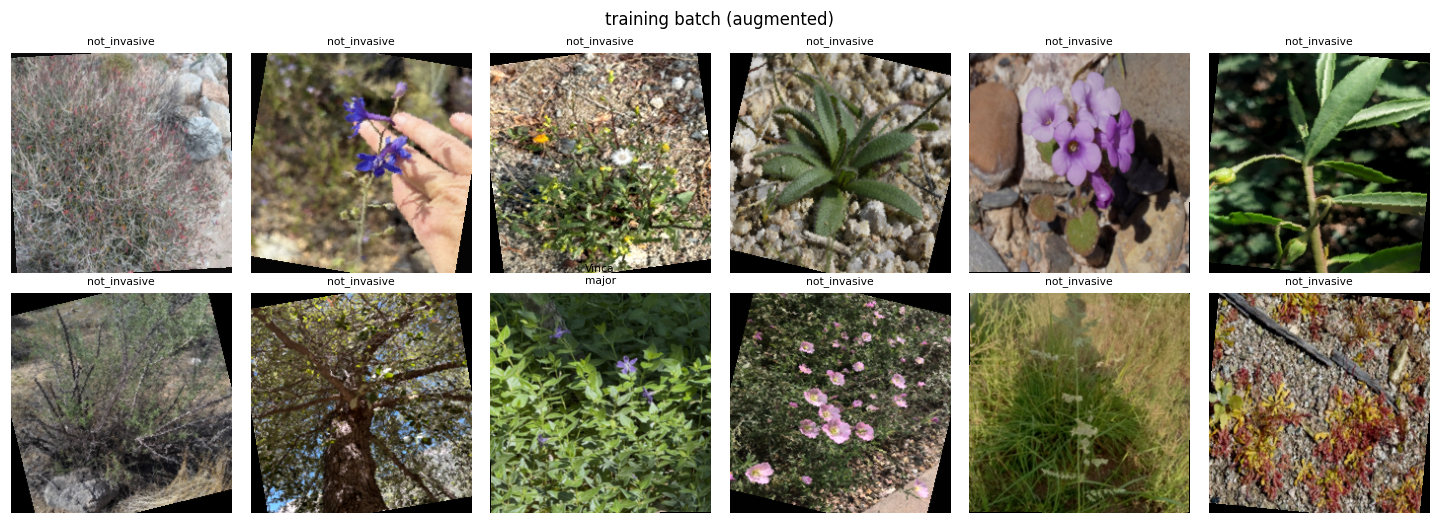

23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.1429 | val macro-F1 0.0198 top1 0.0877 mAP 0.0148 t=0.01 | gnorm 0.07 | 15s | elapsed 0.3m, ~0.5m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0358 | val macro-F1 0.0447 top1 0.2825 mAP 0.0185 t=0.01 | gnorm 0.01 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0112 | val macro-F1 0.3078 top1 0.6602 mAP 0.2860 t=0.04 | gnorm 0.05 | 13s | elapsed 4.8m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0110 | val macro-F1 0.3148 top1 0.6667 mAP 0.2902 t=0.04 | gnorm 0.05 | 13s | elapsed 5.0m, ~0.0m left in full stage *best*
best epoch 23: macro_f1_invasive 0.3181 | top1_acc_all 0.6543 | macro_ap_invasive 0.2953 | top1_recall_invasive 0.4857 | top3_recall_invasive 0.7077 | bin_precision_invasive 0.5635 | bin_recall_invasive 0.6548 | bin_f1_invasive 0.6057 | bin_ap_invasive 0.6224 | bin_auroc_invasive 0.7872 | noninv_precision 0.8376 | noninv_recall 0.7783 | noninv_auroc 0.7872 | macro_f1_all41 0.3300 | threshold 0.03


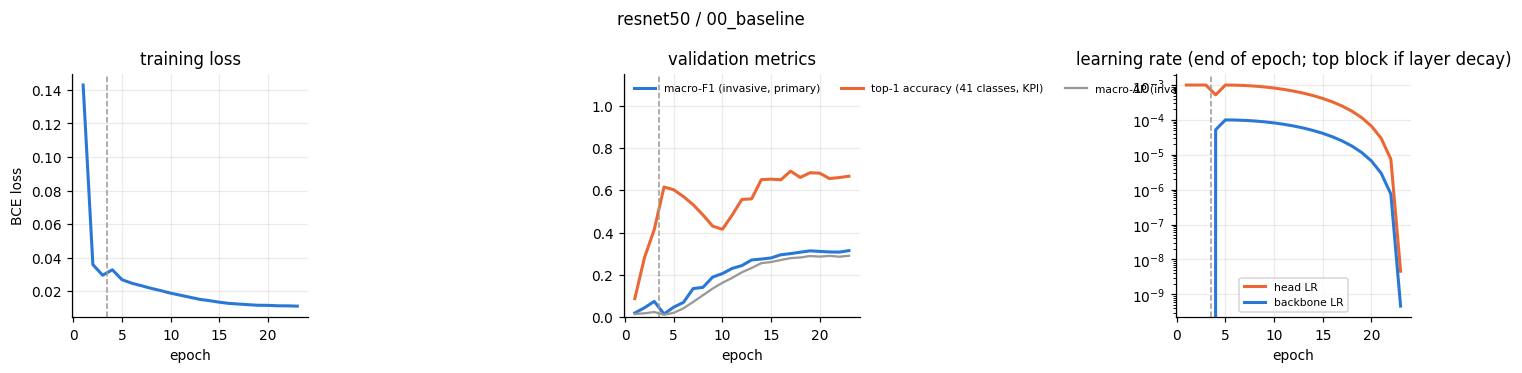

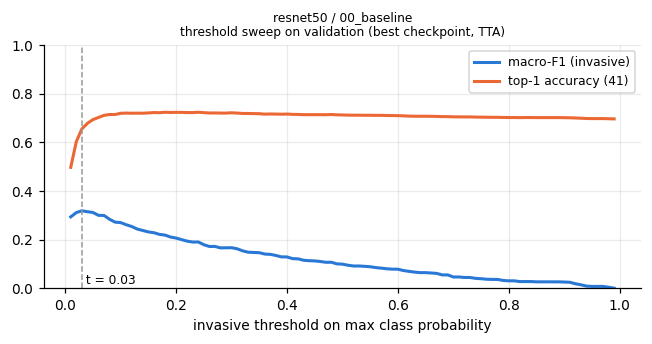

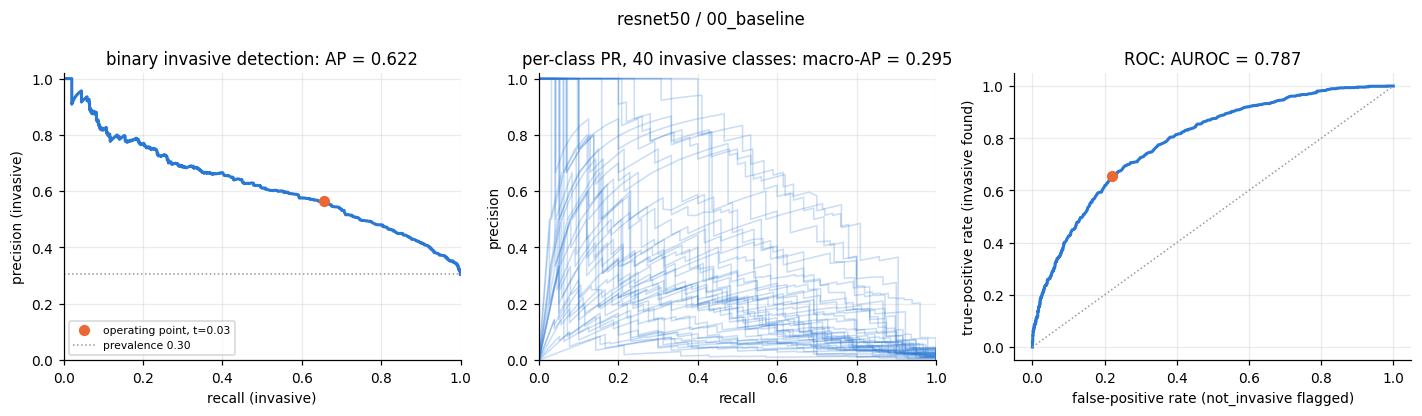

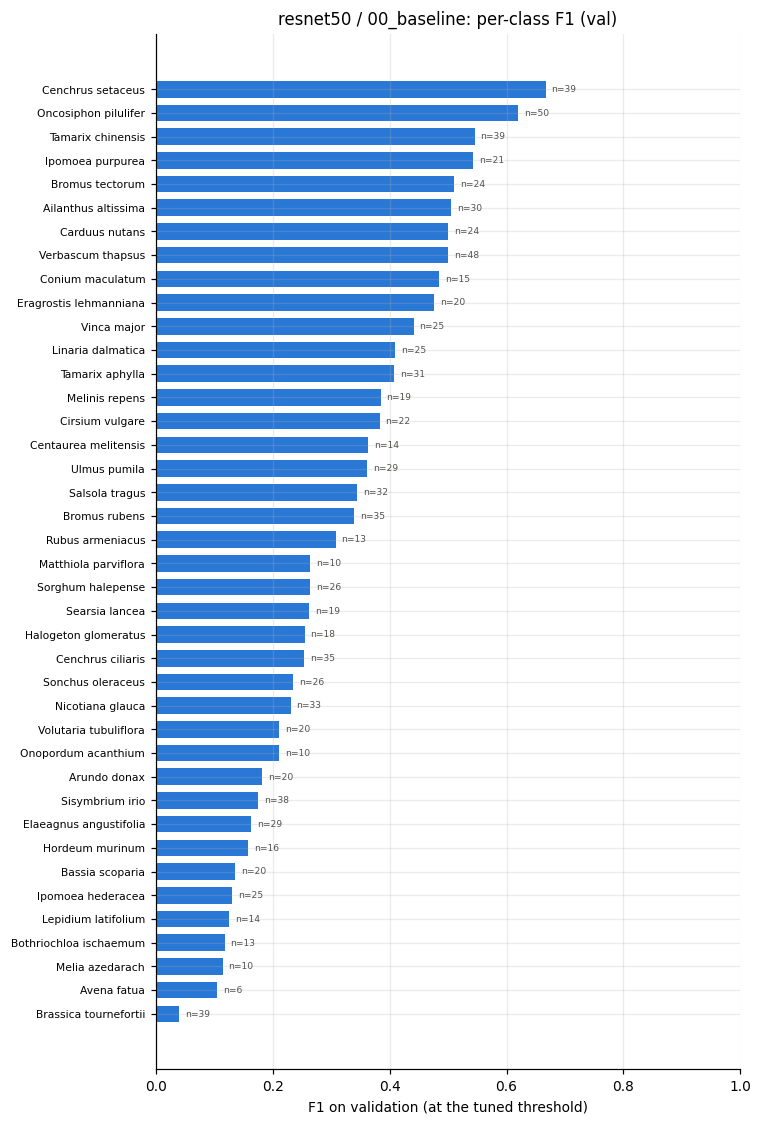

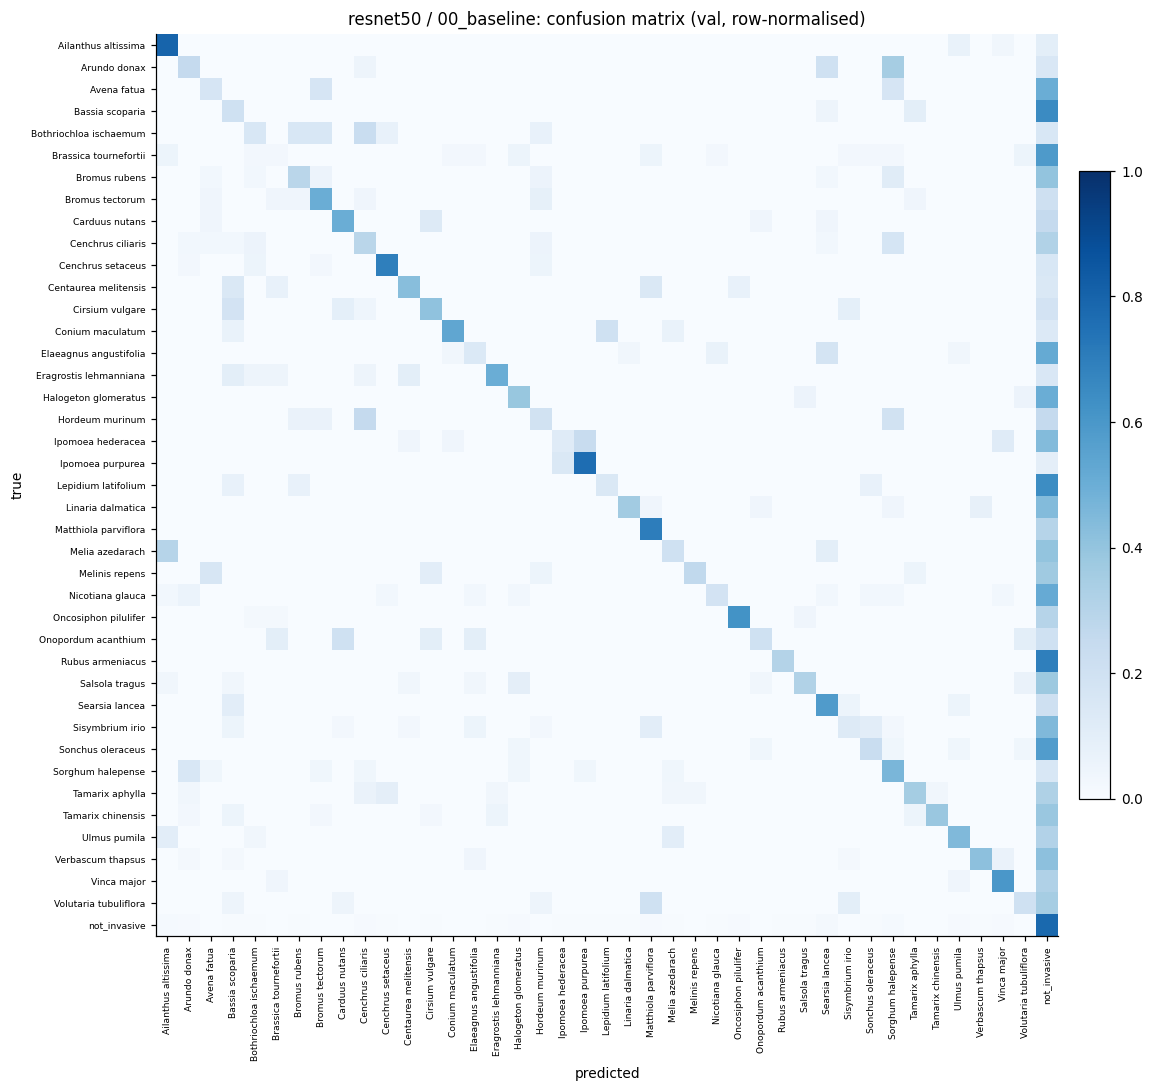

no reference run yet; this run becomes the reference once accepted
00_baseline: accepted. note: decide(): first run, becomes the reference
resnet50: 1 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.318105,0.654275,2026-11-04T18:39


current configuration differs from BASE_CONFIG in: nothing
reference run: 00_baseline


'accepted'

In [ ]:
run_iteration('00_baseline', {})
decide('00_baseline')

### 01 — BCE positive weight 10 (class imbalance)

===== resnet50 / 01_pos_weight_10 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/01_pos_weight_10
changes vs current configuration: {'bce_pos_weight': 10.0}
configuration vs BASE_CONFIG: identical
resnet50: backbone 23.5M params, head 82.0K params, feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7beaf37bfec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError: can only test a child process
<function _MultiProcessingDataLoaderIter.__del__ at 0x7beaf37bfec0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

ep  1/23 [frozen] loss 0.2404 | val macro-F1 0.1122 top1 0.0998 mAP 0.0379 t=0.02 | gnorm 0.10 | 14s | elapsed 0.2m, ~0.5m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.1588 | val macro-F1 0.1566 top1 0.1441 mAP 0.0829 t=0.03 | gnorm 0.07 | 13s | elapsed 0.4m, ~0.2m left in frozen stage + full stage *best*


... (39 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0362 | val macro-F1 0.3360 top1 0.6180 mAP 0.3168 t=0.16 | gnorm 0.29 | 13s | elapsed 4.7m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0355 | val macro-F1 0.3344 top1 0.6753 mAP 0.3214 t=0.26 | gnorm 0.28 | 13s | elapsed 4.9m, ~0.0m left in full stage
best epoch 18: macro_f1_invasive 0.3470 | top1_acc_all 0.7007 | macro_ap_invasive 0.3235 | top1_recall_invasive 0.5092 | top3_recall_invasive 0.7454 | bin_precision_invasive 0.6203 | bin_recall_invasive 0.5540 | bin_f1_invasive 0.5853 | bin_ap_invasive 0.6348 | bin_auroc_invasive 0.7945 | noninv_precision 0.8137 | noninv_recall 0.8517 | noninv_auroc 0.7945 | macro_f1_all41 0.3588 | threshold 0.29


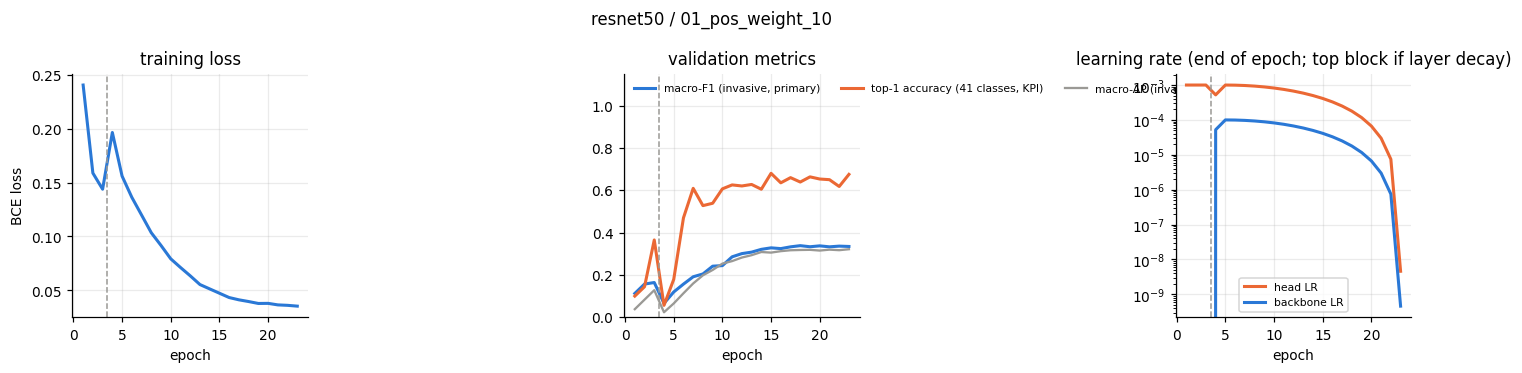

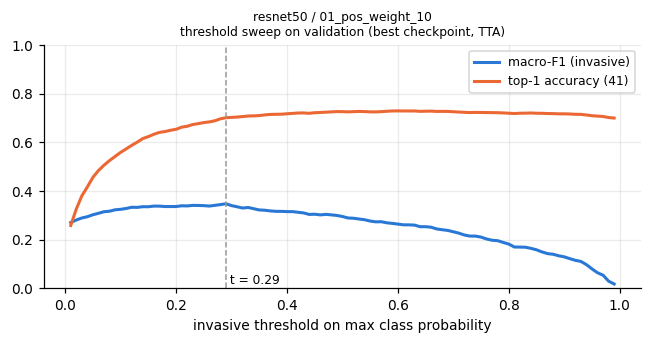

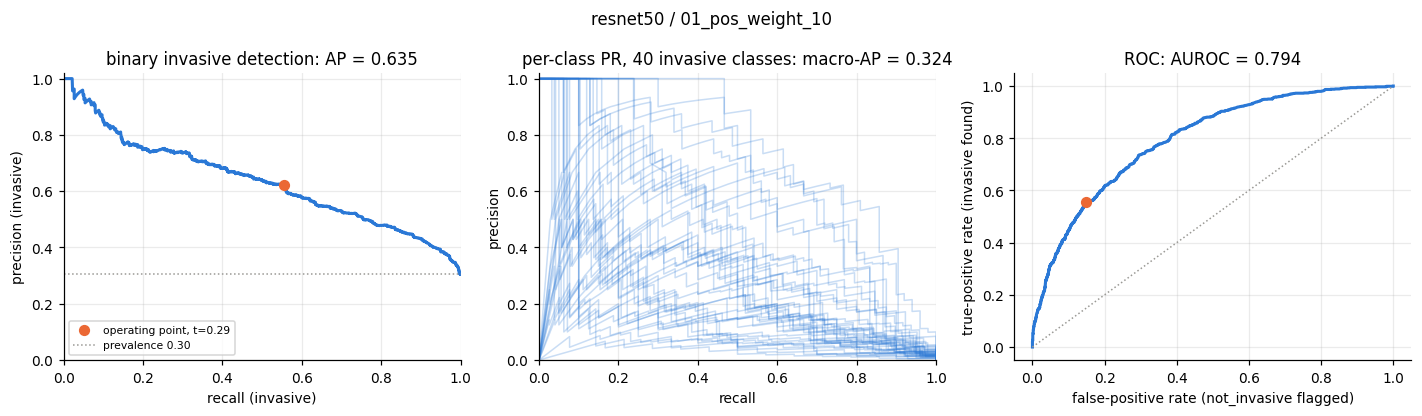

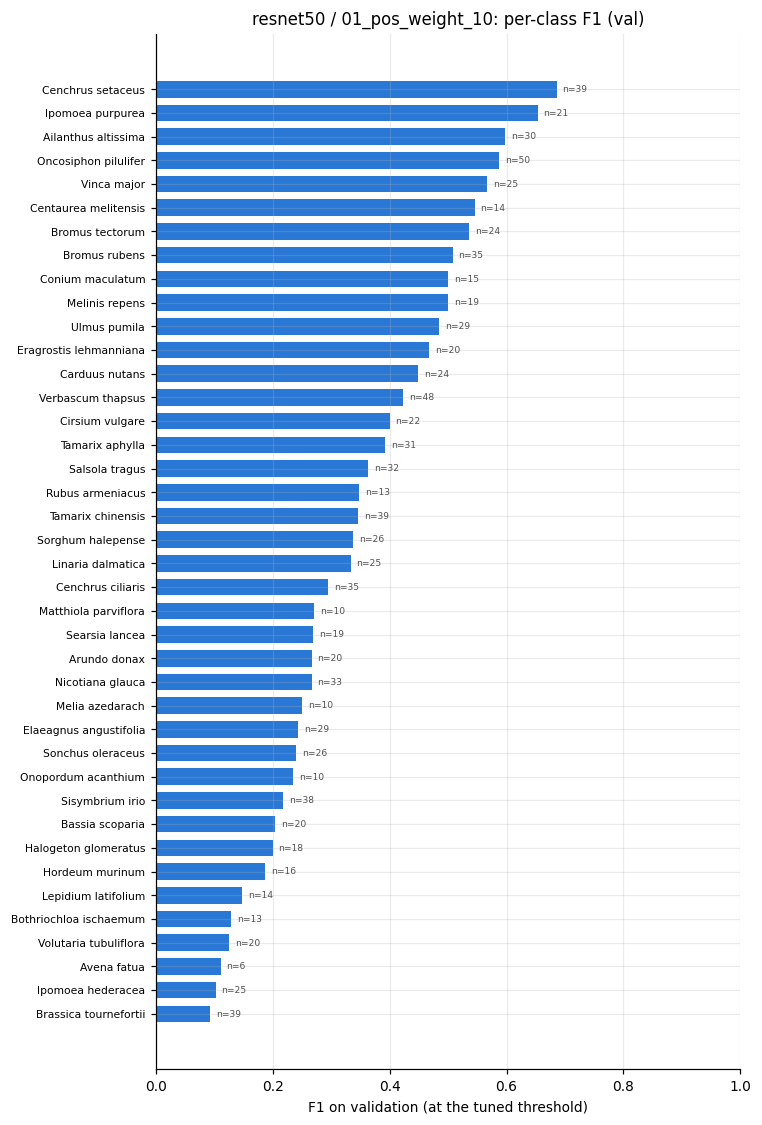

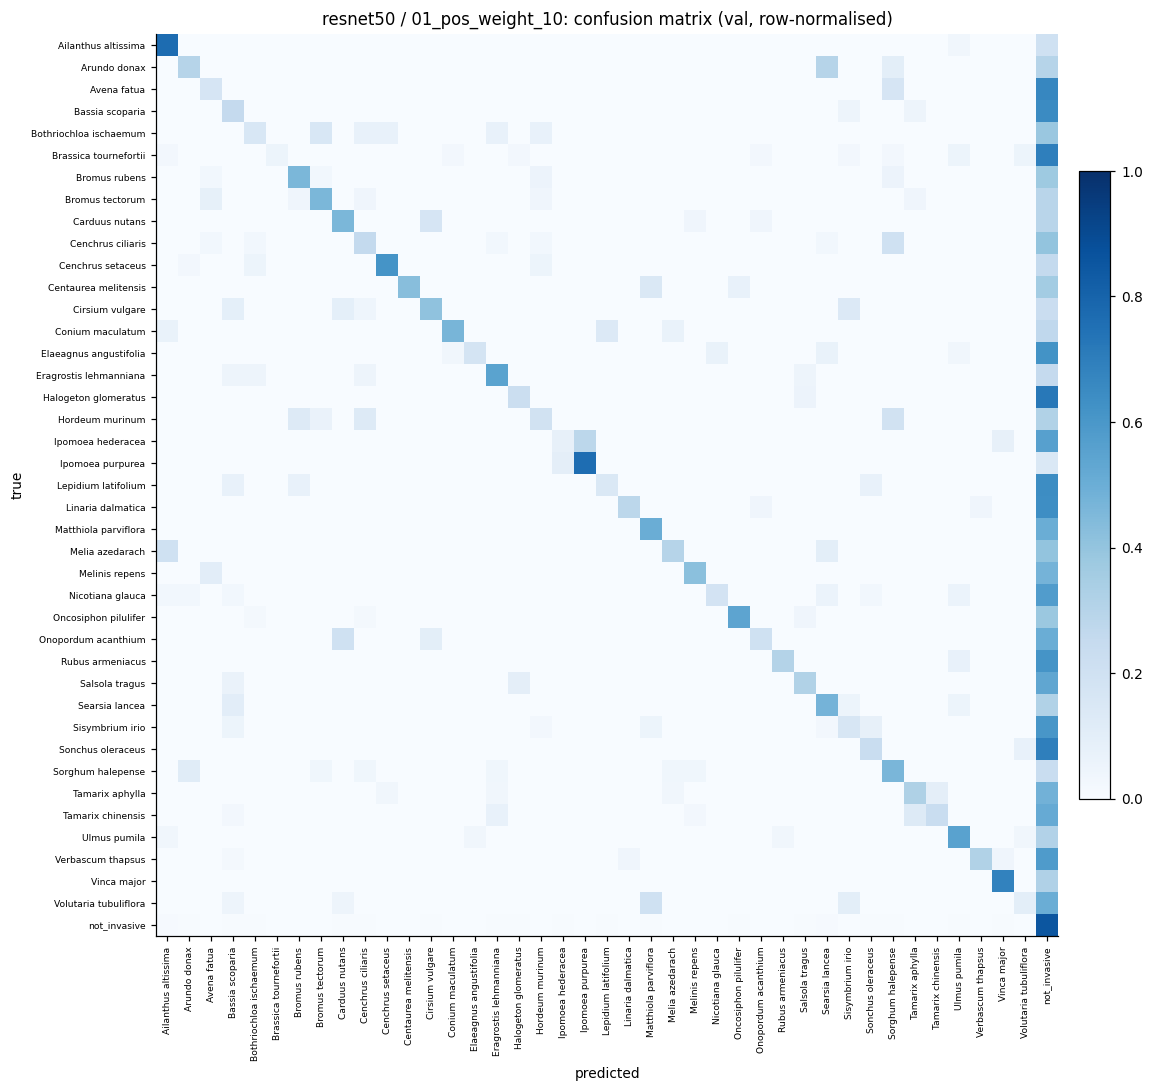

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.3181,0.6543,0.2953,0.4857,0.7077,0.5635,0.6548,0.7872,0.7872,0.03
this run: 01_pos_weight_10,0.3470,0.7007,0.3235,0.5092,0.7454,0.6203,0.5540,0.7945,0.7945,0.29
delta,0.0289,0.0465,0.0282,0.0234,0.0377,0.0568,-0.1008,0.0073,0.0073,0.26


macro-F1 (invasive, primary metric) +0.0289 | top-1 accuracy (KPI) +0.0465. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).
01_pos_weight_10: accepted. note: decide() vs 00_baseline: macro-F1 +0.0289 (need >= +0.01), top-1 +0.0465 (need >= -0.01)
resnet50: 2 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.318105,0.654275,2026-11-04T18:39
01_pos_weight_10,accepted,"{""bce_pos_weight"": 10.0}",0.347014,0.700743,2026-11-04T18:44


current configuration differs from BASE_CONFIG in: {'bce_pos_weight': 10.0}
reference run: 01_pos_weight_10


'accepted'

In [ ]:
run_iteration('01_pos_weight_10', {'bce_pos_weight': 10.0})
decide('01_pos_weight_10')

### 02 — additional frozen epochs

===== resnet50 / 02_frozen_epochs_8 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/02_frozen_epochs_8
changes vs current configuration: {'frozen_epochs': 8}
configuration vs BASE_CONFIG: {'bce_pos_weight': 10.0}
resnet50: backbone 23.5M params, head 82.0K params, feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0
28 epochs (8 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/28 [frozen] loss 0.2404 | val macro-F1 0.1122 top1 0.0998 mAP 0.0379 t=0.02 | gnorm 0.10 | 13s | elapsed 0.2m, ~1.5m left in frozen stage + full stage *best*


epoch 2/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/28 [frozen] loss 0.1588 | val macro-F1 0.1566 top1 0.1441 mAP 0.0829 t=0.03 | gnorm 0.07 | 12s | elapsed 0.4m, ~1.2m left in frozen stage + full stage *best*


epoch 3/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (48 outputs left out)

epoch 27/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 27/28 [full  ] loss 0.0304 | val macro-F1 0.3542 top1 0.6949 mAP 0.3399 t=0.30 | gnorm 0.30 | 12s | elapsed 5.7m, ~0.2m left in full stage


epoch 28/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 28/28 [full  ] loss 0.0305 | val macro-F1 0.3544 top1 0.7042 mAP 0.3439 t=0.33 | gnorm 0.30 | 12s | elapsed 5.9m, ~0.0m left in full stage
best epoch 25: macro_f1_invasive 0.3702 | top1_acc_all 0.7209 | macro_ap_invasive 0.3514 | top1_recall_invasive 0.5224 | top3_recall_invasive 0.7464 | bin_precision_invasive 0.6515 | bin_recall_invasive 0.5255 | bin_f1_invasive 0.5817 | bin_ap_invasive 0.6642 | bin_auroc_invasive 0.8071 | noninv_precision 0.8087 | noninv_recall 0.8771 | noninv_auroc 0.8071 | macro_f1_all41 0.3817 | threshold 0.34


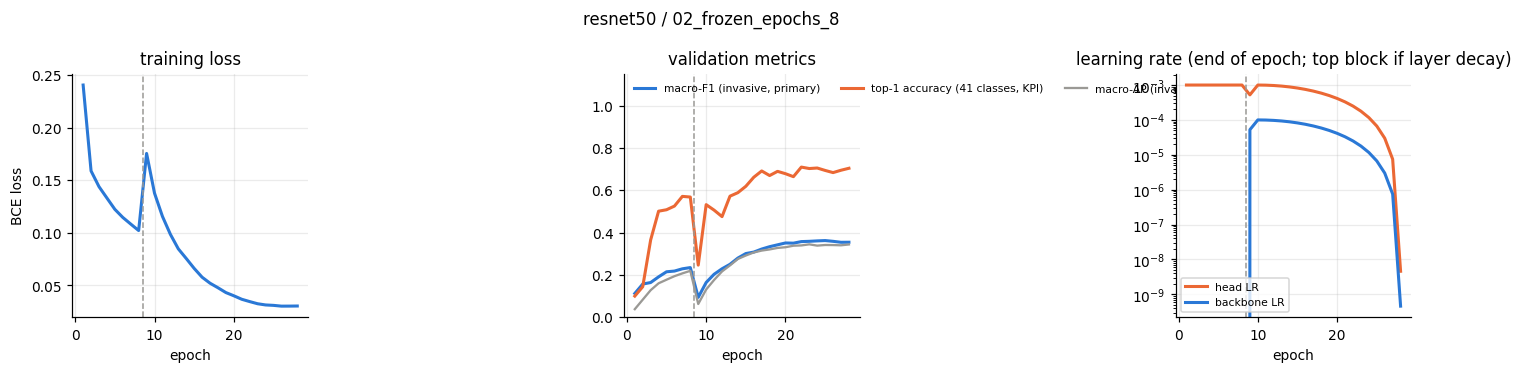

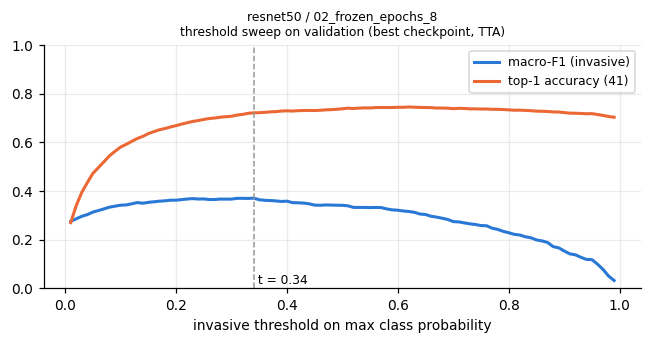

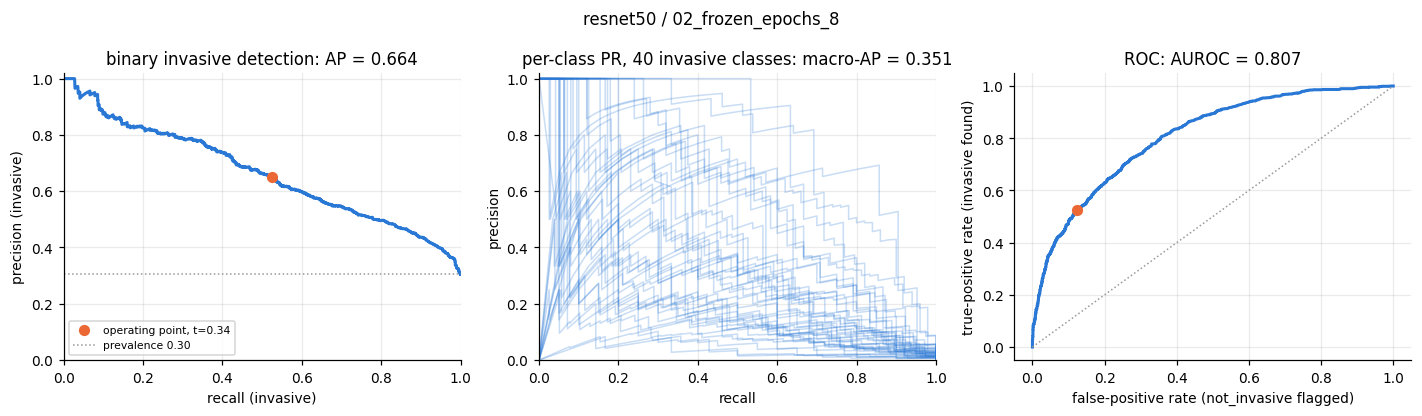

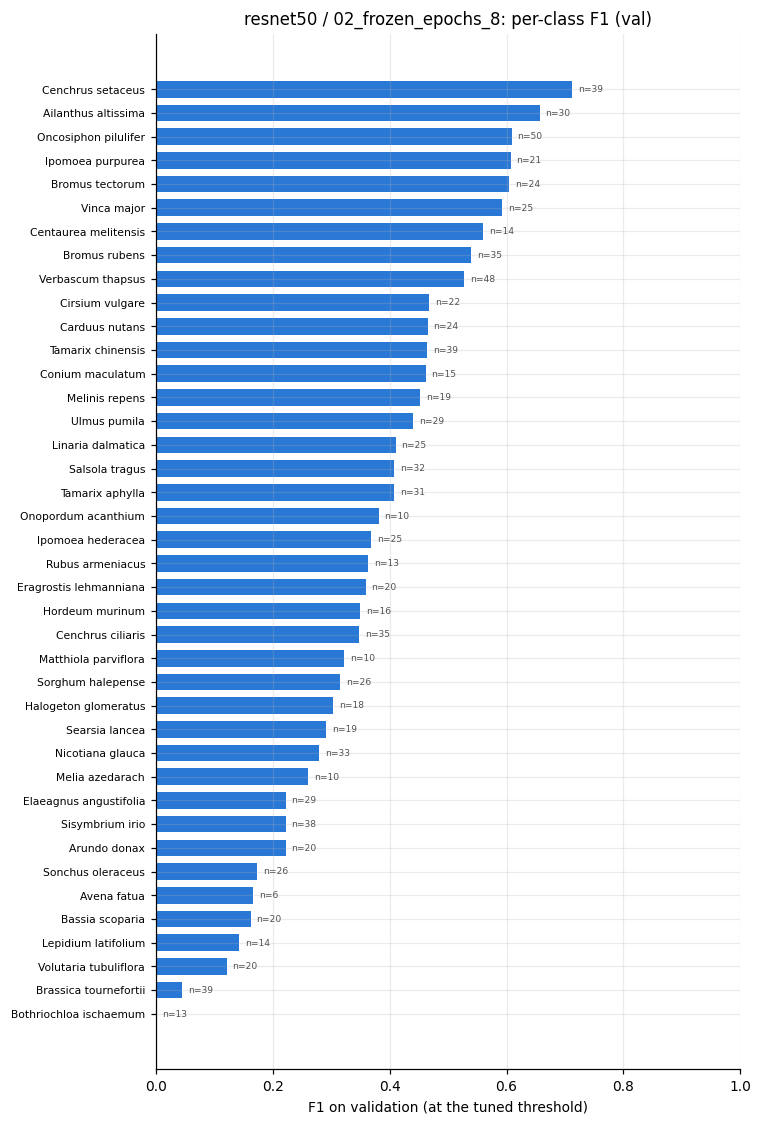

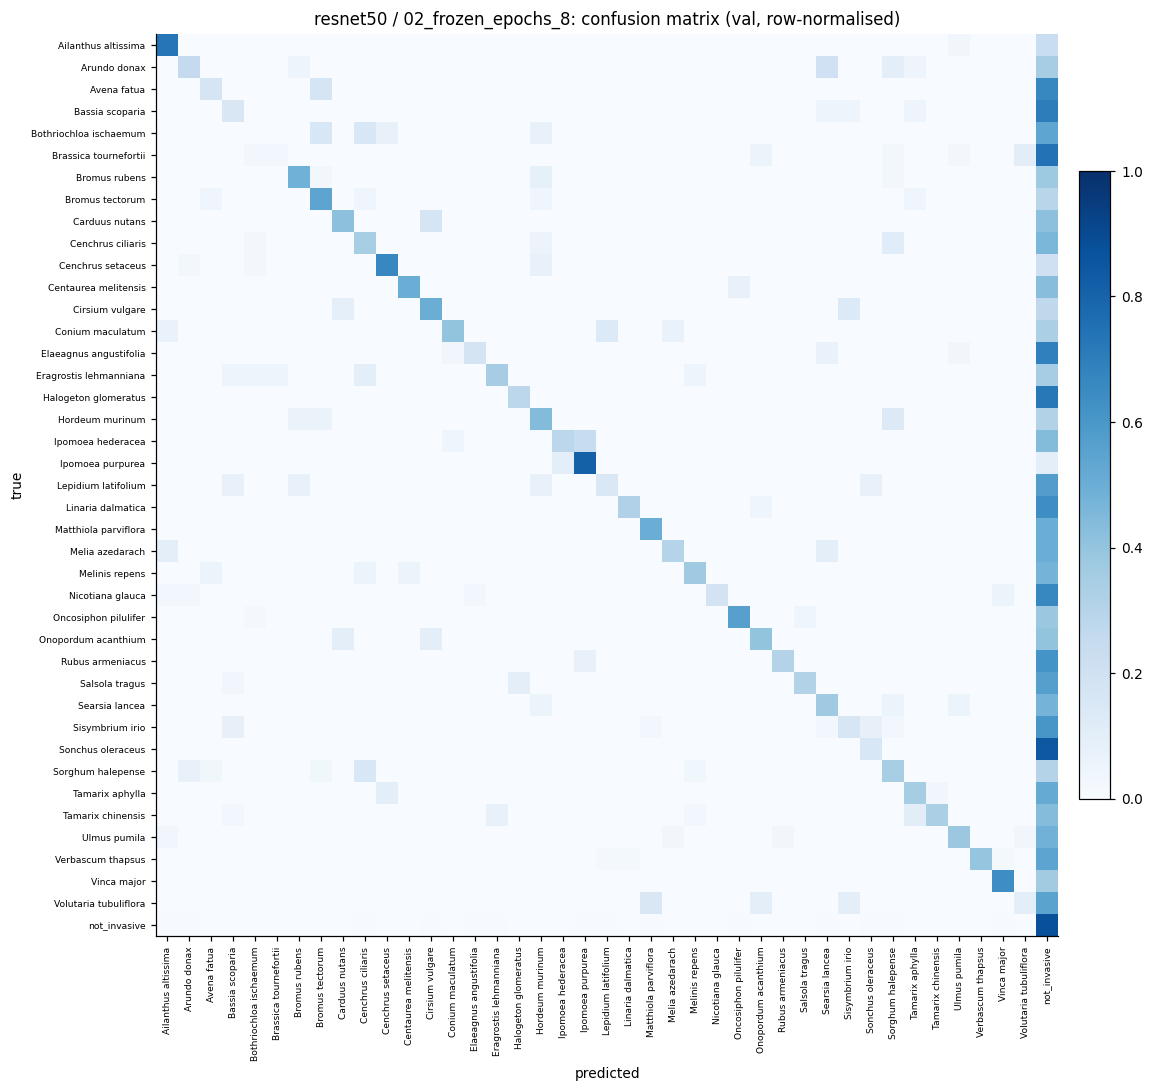

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 01_pos_weight_10,0.3470,0.7007,0.3235,0.5092,0.7454,0.6203,0.5540,0.7945,0.7945,0.29
this run: 02_frozen_epochs_8,0.3702,0.7209,0.3514,0.5224,0.7464,0.6515,0.5255,0.8071,0.8071,0.34
delta,0.0232,0.0201,0.0279,0.0132,0.0010,0.0312,-0.0285,0.0126,0.0126,0.05


macro-F1 (invasive, primary metric) +0.0232 | top-1 accuracy (KPI) +0.0201. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).
02_frozen_epochs_8: accepted. note: decide() vs 01_pos_weight_10: macro-F1 +0.0232 (need >= +0.01), top-1 +0.0201 (need >= -0.01)
resnet50: 3 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.318105,0.654275,2026-11-04T18:39
01_pos_weight_10,accepted,"{""bce_pos_weight"": 10.0}",0.347014,0.700743,2026-11-04T18:44
02_frozen_epochs_8,accepted,"{""frozen_epochs"": 8}",0.370170,0.720880,2026-11-04T18:50


current configuration differs from BASE_CONFIG in: {'frozen_epochs': 8, 'bce_pos_weight': 10.0}
reference run: 02_frozen_epochs_8


'accepted'

In [ ]:
run_iteration('02_frozen_epochs_8', {'frozen_epochs': 8})
decide('02_frozen_epochs_8')

### 03 — MixUp 0.2 + label smoothing 0.05

===== resnet50 / 03_mixup_labelsmooth -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/03_mixup_labelsmooth
changes vs current configuration: {'mixup_alpha': 0.2, 'label_smoothing': 0.05}
configuration vs BASE_CONFIG: {'frozen_epochs': 8, 'bce_pos_weight': 10.0}
resnet50: backbone 23.5M params, head 82.0K params, feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0
28 epochs (8 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/28 [frozen] loss 0.6920 | val macro-F1 0.1201 top1 0.1227 mAP 0.0978 t=0.26 | gnorm 0.07 | 13s | elapsed 0.2m, ~1.5m left in frozen stage + full stage *best*


epoch 2/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/28 [frozen] loss 0.6738 | val macro-F1 0.1802 top1 0.5118 mAP 0.1778 t=0.32 | gnorm 0.05 | 12s | elapsed 0.4m, ~1.2m left in frozen stage + full stage *best*


epoch 3/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (48 outputs left out)

epoch 27/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 27/28 [full  ] loss 0.6519 | val macro-F1 0.3662 top1 0.6778 mAP 0.3624 t=0.44 | gnorm 0.08 | 12s | elapsed 5.6m, ~0.2m left in full stage *best*


epoch 28/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 28/28 [full  ] loss 0.6514 | val macro-F1 0.3662 top1 0.6540 mAP 0.3645 t=0.42 | gnorm 0.08 | 12s | elapsed 5.8m, ~0.0m left in full stage
best epoch 27: macro_f1_invasive 0.3741 | top1_acc_all 0.6660 | macro_ap_invasive 0.3731 | top1_recall_invasive 0.5468 | top3_recall_invasive 0.7485 | bin_precision_invasive 0.5538 | bin_recall_invasive 0.6813 | bin_f1_invasive 0.6110 | bin_ap_invasive 0.6470 | bin_auroc_invasive 0.8003 | noninv_precision 0.8450 | noninv_recall 0.7600 | noninv_auroc 0.8003 | macro_f1_all41 0.3845 | threshold 0.42


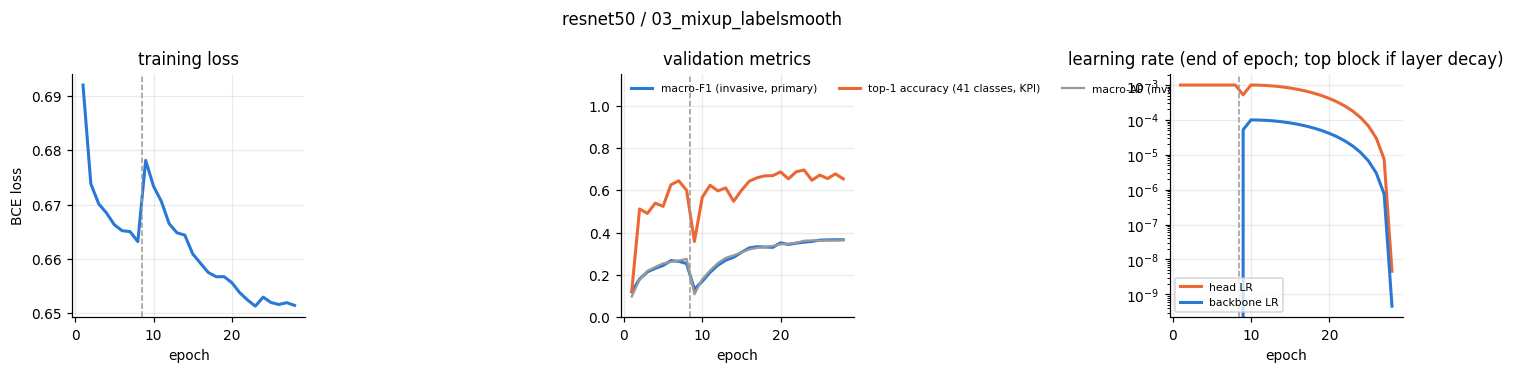

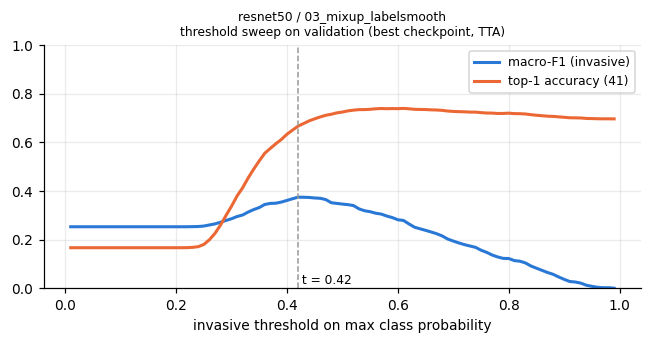

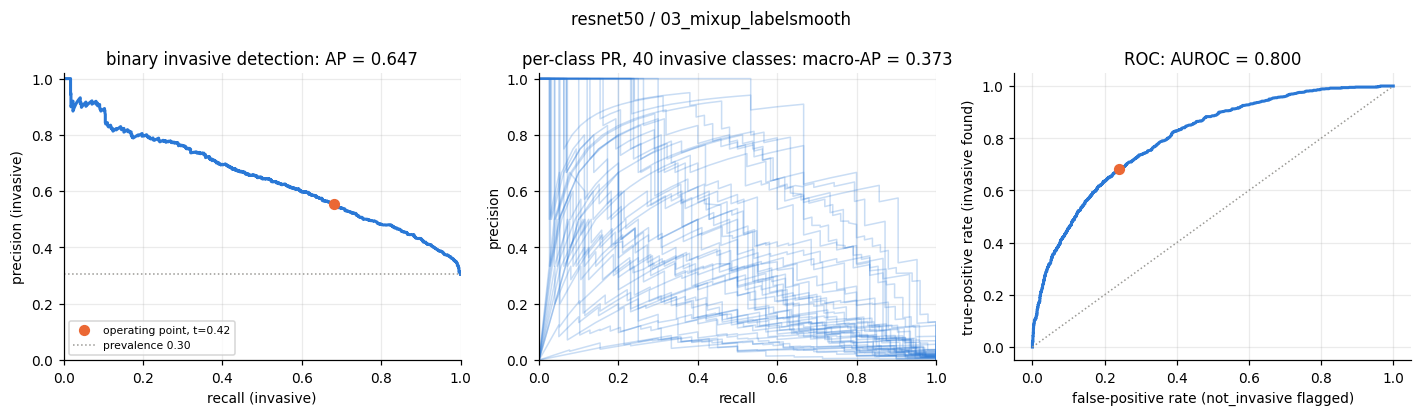

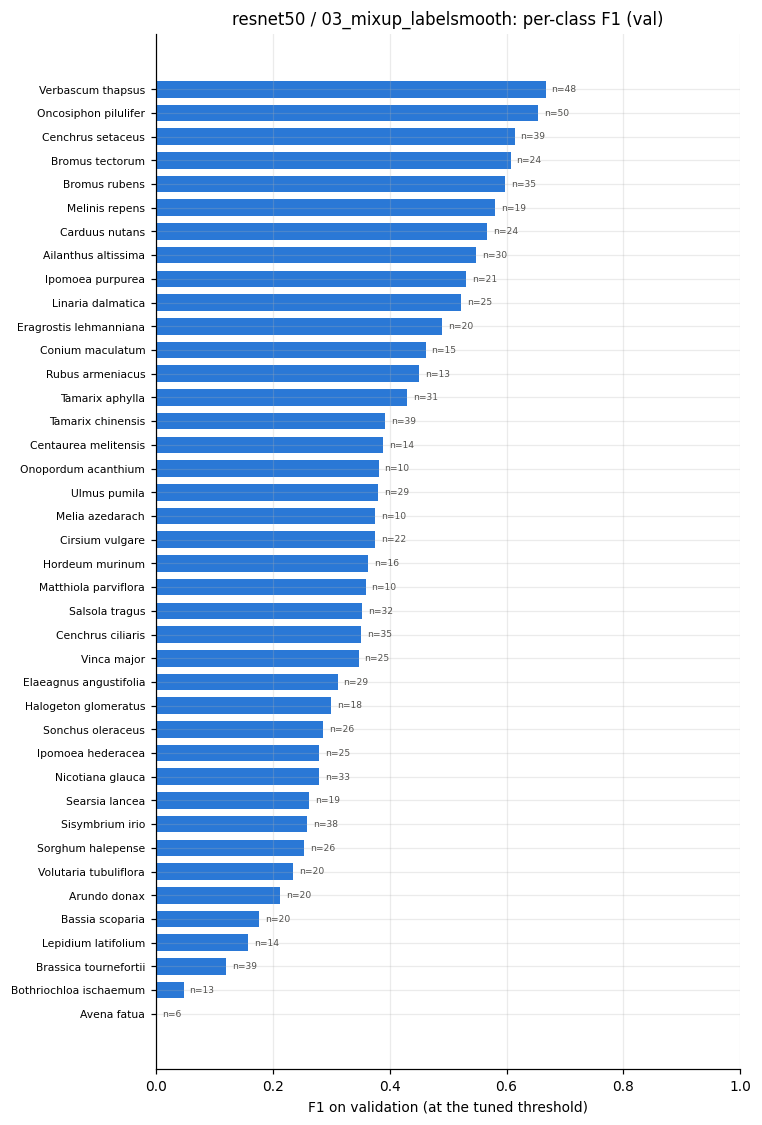

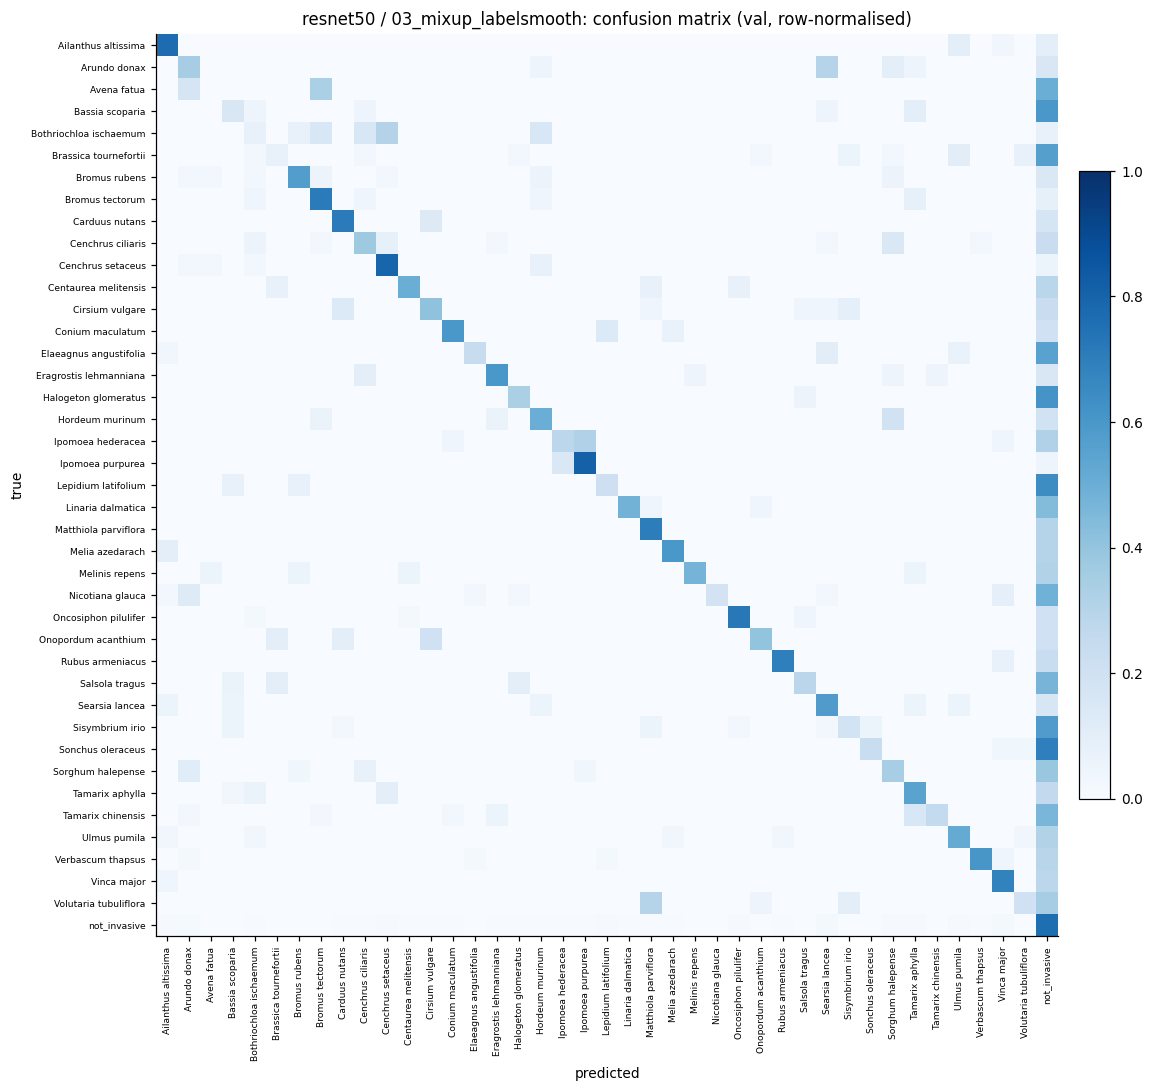

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 02_frozen_epochs_8,0.3702,0.7209,0.3514,0.5224,0.7464,0.6515,0.5255,0.8071,0.8071,0.34
this run: 03_mixup_labelsmooth,0.3741,0.6660,0.3731,0.5468,0.7485,0.5538,0.6813,0.8003,0.8003,0.42
delta,0.0039,-0.0548,0.0217,0.0244,0.0020,-0.0977,0.1558,-0.0068,-0.0068,0.08


macro-F1 (invasive, primary metric) +0.0039 | top-1 accuracy (KPI) -0.0548. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).
03_mixup_labelsmooth: rejected. note: decide() vs 02_frozen_epochs_8: macro-F1 +0.0039 (need >= +0.01), top-1 -0.0548 (need >= -0.01)
resnet50: 4 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.318105,0.654275,2026-11-04T18:39
01_pos_weight_10,accepted,"{""bce_pos_weight"": 10.0}",0.347014,0.700743,2026-11-04T18:44
02_frozen_epochs_8,accepted,"{""frozen_epochs"": 8}",0.370170,0.720880,2026-11-04T18:50
03_mixup_labelsmooth,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.374111,0.666047,2026-11-04T18:56


current configuration differs from BASE_CONFIG in: {'frozen_epochs': 8, 'bce_pos_weight': 10.0}
reference run: 02_frozen_epochs_8


'rejected'

In [ ]:
run_iteration('03_mixup_labelsmooth', {'mixup_alpha': 0.2, 'label_smoothing': 0.05})
decide('03_mixup_labelsmooth')

### 04 — higher backbone LR (CNNs usually take more than ViTs)

===== resnet50 / 04_backbone_lr_3e-4 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/04_backbone_lr_3e-4
changes vs current configuration: {'backbone_lr': 0.0003}
configuration vs BASE_CONFIG: {'frozen_epochs': 8, 'bce_pos_weight': 10.0}
resnet50: backbone 23.5M params, head 82.0K params, feat_dim 2048 | timm resnet50.a1_in1k, pool=SelectAdaptivePool2d(pool_type=avg, flatten=Flatten(start_dim=1, end_dim=-1)), drop_path=0.0
28 epochs (8 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/28 [frozen] loss 0.2404 | val macro-F1 0.1122 top1 0.0998 mAP 0.0379 t=0.02 | gnorm 0.10 | 13s | elapsed 0.2m, ~1.5m left in frozen stage + full stage *best*


epoch 2/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/28 [frozen] loss 0.1588 | val macro-F1 0.1566 top1 0.1441 mAP 0.0829 t=0.03 | gnorm 0.07 | 12s | elapsed 0.4m, ~1.2m left in frozen stage + full stage *best*


epoch 3/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (48 outputs left out)

epoch 27/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 27/28 [full  ] loss 0.0067 | val macro-F1 0.4233 top1 0.7200 mAP 0.4264 t=0.11 | gnorm 0.10 | 12s | elapsed 5.7m, ~0.2m left in full stage


epoch 28/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 28/28 [full  ] loss 0.0071 | val macro-F1 0.4266 top1 0.7556 mAP 0.4320 t=0.29 | gnorm 0.11 | 12s | elapsed 5.9m, ~0.0m left in full stage
best epoch 25: macro_f1_invasive 0.4366 | top1_acc_all 0.7673 | macro_ap_invasive 0.4430 | top1_recall_invasive 0.5937 | top3_recall_invasive 0.8004 | bin_precision_invasive 0.7707 | bin_recall_invasive 0.4827 | bin_f1_invasive 0.5936 | bin_ap_invasive 0.7224 | bin_auroc_invasive 0.8355 | noninv_precision 0.8056 | noninv_recall 0.9372 | noninv_auroc 0.8355 | macro_f1_all41 0.4471 | threshold 0.34


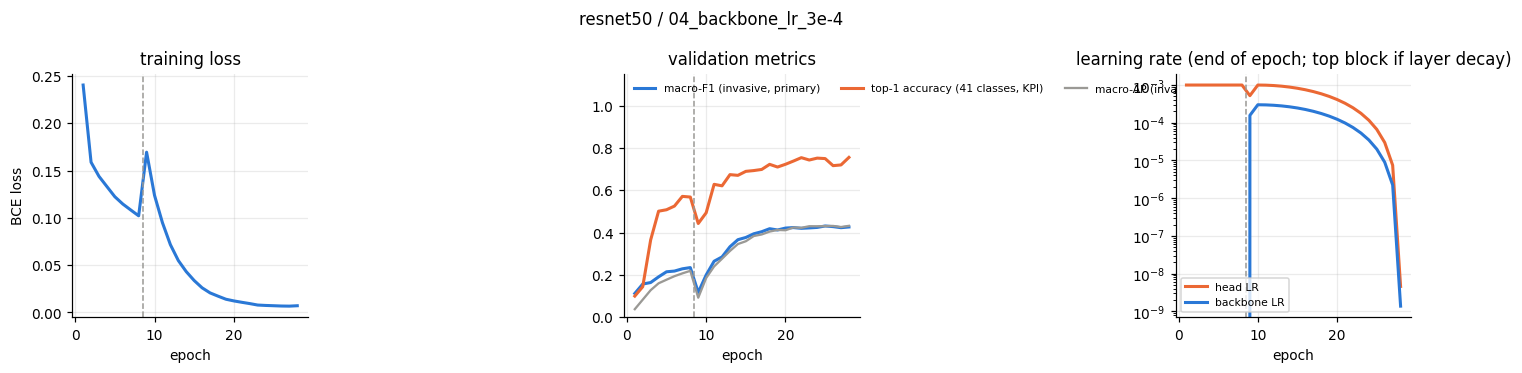

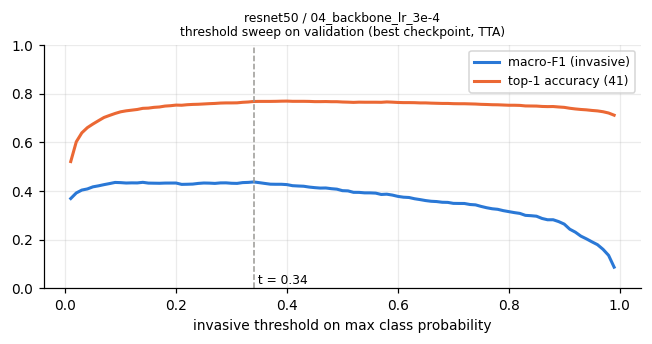

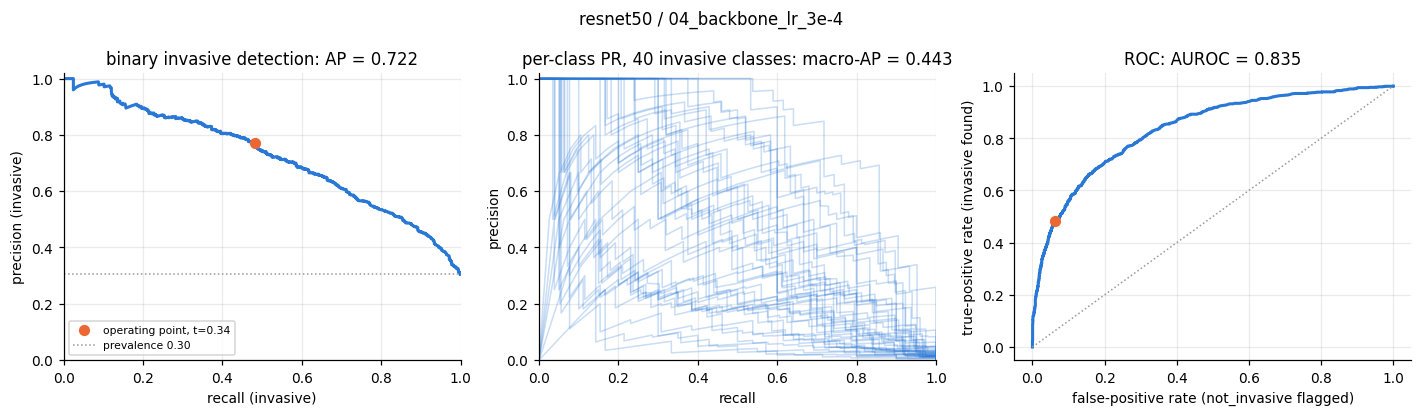

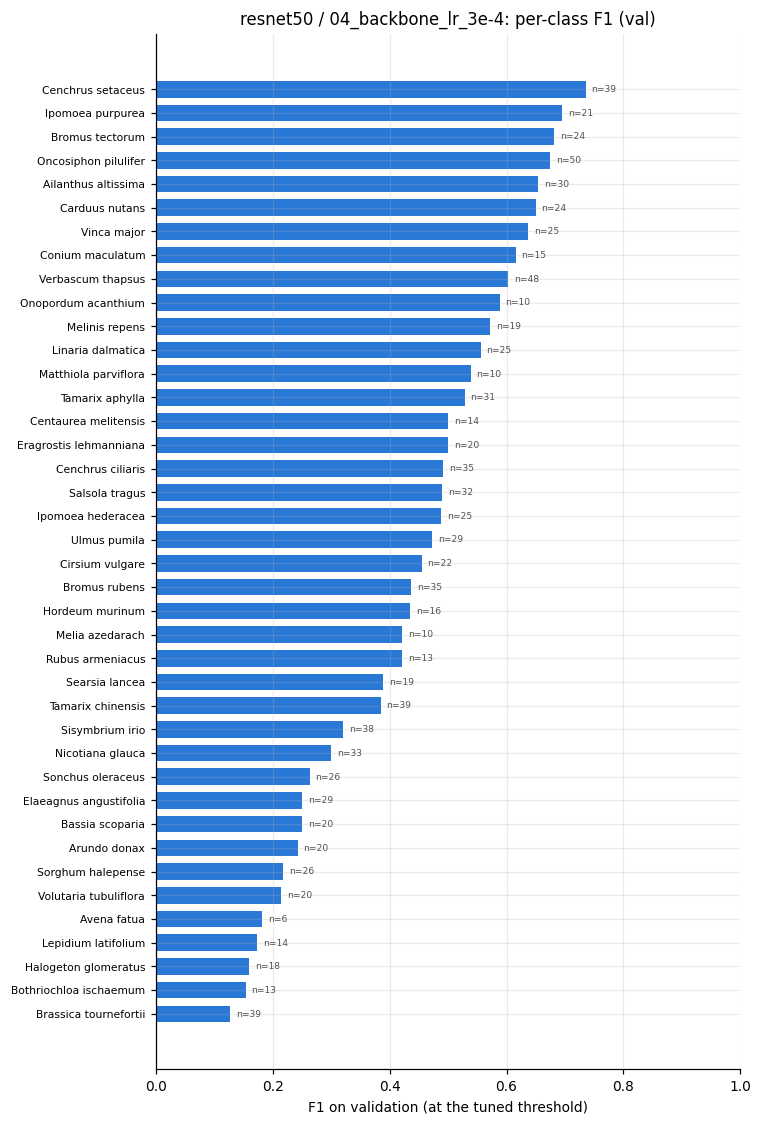

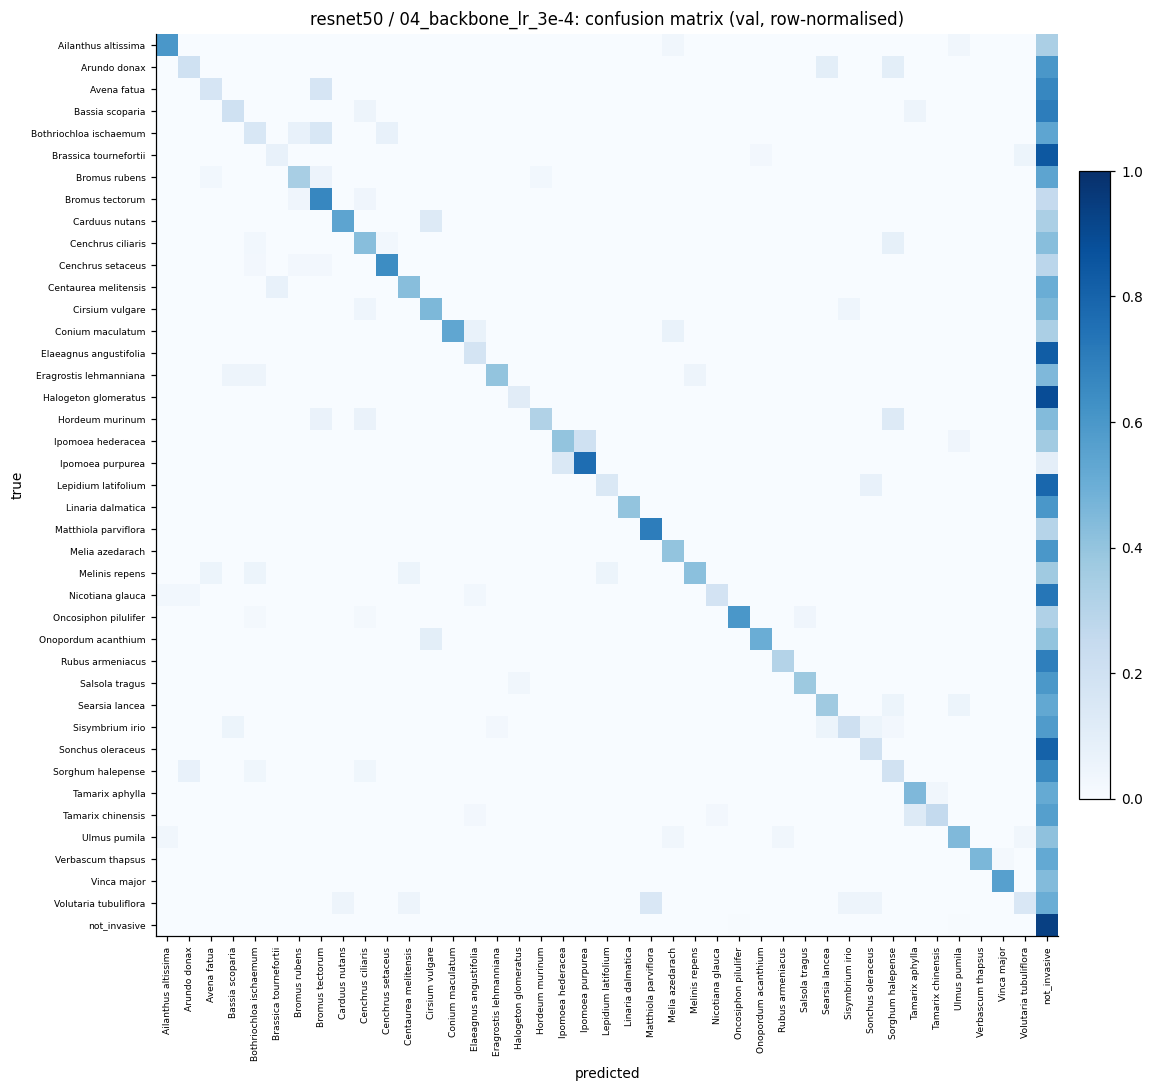

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 02_frozen_epochs_8,0.3702,0.7209,0.3514,0.5224,0.7464,0.6515,0.5255,0.8071,0.8071,0.34
this run: 04_backbone_lr_3e-4,0.4366,0.7673,0.4430,0.5937,0.8004,0.7707,0.4827,0.8355,0.8355,0.34
delta,0.0665,0.0465,0.0915,0.0713,0.0540,0.1192,-0.0428,0.0284,0.0284,0.00


macro-F1 (invasive, primary metric) +0.0665 | top-1 accuracy (KPI) +0.0465. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).
04_backbone_lr_3e-4: accepted. note: decide() vs 02_frozen_epochs_8: macro-F1 +0.0665 (need >= +0.01), top-1 +0.0465 (need >= -0.01)
resnet50: 5 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/resnet50/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.318105,0.654275,2026-11-04T18:39
01_pos_weight_10,accepted,"{""bce_pos_weight"": 10.0}",0.347014,0.700743,2026-11-04T18:44
02_frozen_epochs_8,accepted,"{""frozen_epochs"": 8}",0.370170,0.720880,2026-11-04T18:50
03_mixup_labelsmooth,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.374111,0.666047,2026-11-04T18:56
04_backbone_lr_3e-4,accepted,"{""backbone_lr"": 0.0003}",0.436623,0.767348,2026-11-04T19:02


current configuration differs from BASE_CONFIG in: {'frozen_epochs': 8, 'backbone_lr': 0.0003, 'bce_pos_weight': 10.0}
reference run: 04_backbone_lr_3e-4


'accepted'

In [ ]:
run_iteration('04_backbone_lr_3e-4', {'backbone_lr': 0.0003})
decide('04_backbone_lr_3e-4')

### Further iterations

Add a cell per change: `run_iteration("<nn>_<name>", {<one or two config keys>})` followed by `decide("<nn>_<name>")`. Then run `compare_model_runs.ipynb` to compare models.